# Demo: AI-Assisted Pattern and Anomaly Visualization

**Unit 4 · AI-Assisted and Advanced Visualization · Lecture 4**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

This notebook walks through every topic of the lecture on **one synthetic dataset** (online payment transactions with planted anomalies and a known ground truth) plus a few small synthetic series for the trend, clustering, anomaly-type and uncertainty sections. It needs no internet and **no API key**.

> **About the "AI" in this notebook.** The "detector" is a real but small algorithm (an Isolation Forest from scikit-learn). Because we planted the anomalies ourselves, we know the **ground truth** and can measure exactly how often the AI is right, wrong, or silent. In real projects the ground truth comes from human review, which is why the human-verification sections matter.

| Section | Lecture topic |
|---|---|
| 1 | Why AI-assisted pattern and anomaly visualization; the pipeline |
| 2 | Data abstraction; derived attributes (score, cluster ID, flag) and their channels |
| 3 | What is a pattern; what human perception contributes (Gestalt) |
| 4–6 | Histograms, density plots and the distribution of AI scores |
| 7–9 | Scatterplots, correlograms, PCA |
| 10–11 | Automated trend and cluster detection; showing clusters honestly |
| 12–13 | Outlier identification; detector families; anomaly detection |
| 14 | Point, contextual and collective anomalies |
| 15–16 | Visual highlighting (pop-out, channels) and automated annotation |
| 17 | Human verification: the review queue and what the reviewer needs |
| 18–19 | False positives / negatives, thresholds, precision, recall, F1, the accuracy trap |
| 20 | Uncertainty in algorithmic findings: error bars, bands, outcome plots, frequency framing |
| 21–22 | Saliency, attention and overemphasis; graded emphasis; an anomaly review view |
| 23 | Numericals 1–4 |

In [1]:
import itertools, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE, LIGHT = "#bdbdbd", "#d95f02", "#4c78a8", "#e6e6e6"

## 1 · Why AI-assisted pattern and anomaly visualization?

Datasets are often too large to inspect item by item. An algorithm can **scan every item and rank them**; human vision is excellent at seeing structure *if the design lets it* (Ware G1.1). The combination:

**the machine proposes candidates → the visualization presents them → the human judges them → feedback tunes the model and thresholds.**

The risk is that algorithmic output misleads: false alarms, missed cases, over-trust. We build a synthetic table of **3,000 online payments** with **45 planted anomalies of three kinds**, so we always know the truth:

| Planted kind | What is unusual | Visible in one variable? |
|---|---|---|
| A · huge amount | amount 3–8× the usual for the basket | yes (amount) |
| B · amount/basket mismatch | ₹1,800–3,500 for a single item | **no**: each value is normal on its own |
| C · far & at night | 25–70 km from home, midnight–4 am | partly (distance, hour) |

About 3% of genuine customers are **travellers** shopping 20–60 km from home: unusual, but normal. They will tempt the detector into false alarms.

In [2]:
rng = np.random.default_rng(42)
N = 3000
hour_w = np.array([1, .6, .4, .3, .3, .5, 1, 2, 3, 4, 5, 5, 6, 6, 5, 5, 5, 6, 7, 7, 6, 4, 3, 2], float)
items = rng.poisson(3, N) + 1
amount = items * rng.lognormal(np.log(350), 0.45, N)
tx = pd.DataFrame({
    "tx_id": [f"T{100000 + i}" for i in range(N)],
    "hour": rng.choice(24, N, p=hour_w / hour_w.sum()),
    "items": items,
    "amount": amount,
    "km_from_home": rng.gamma(1.6, 2.2, N).clip(0.1, 35),
    "account_age_days": rng.integers(30, 2500, N),
    "category": rng.choice(["Grocery", "Electronics", "Fashion", "Travel"], N, p=[.5, .2, .2, .1]),
    "kind": "normal",
})
trav = rng.random(N) < 0.03
tx.loc[trav, "km_from_home"] = rng.uniform(20, 60, trav.sum())              # legitimate travellers: unusual but normal
idx = rng.choice(np.where(~trav)[0], 45, replace=False)
a, b, c = idx[:15], idx[15:30], idx[30:]
tx.loc[a, "amount"] *= rng.uniform(3, 8, 15); tx.loc[a, "kind"] = "A: huge amount"
tx.loc[b, "items"] = 1; tx.loc[b, "amount"] = rng.uniform(1800, 3500, 15); tx.loc[b, "kind"] = "B: amount/basket mismatch"
tx.loc[c, "km_from_home"] = rng.uniform(25, 70, 15); tx.loc[c, "hour"] = rng.integers(0, 5, 15); tx.loc[c, "kind"] = "C: far & at night"
tx["amount"] = tx["amount"].round(0)
tx["km_from_home"] = tx["km_from_home"].round(1)
tx["is_anomaly"] = (tx["kind"] != "normal").astype(int)
print(tx.shape, "| anomalies:", tx.is_anomaly.sum(), f"({tx.is_anomaly.mean():.1%})")
tx.head()

(3000, 9) | anomalies: 45 (1.5%)


,tx_id,hour,items,amount,km_from_home,account_age_days,category,kind,is_anomaly
0,T100000,8,5,1715.0,5.7,343,Grocery,normal,0
1,T100001,15,5,988.0,2.3,2310,Fashion,normal,0
2,T100002,16,6,2160.0,4.8,529,Grocery,normal,0
3,T100003,20,2,299.0,6.1,1689,Grocery,normal,0
4,T100004,8,8,2155.0,0.4,71,Grocery,normal,0


### The AI detector
An **Isolation Forest** isolates each point with random splits; anomalies need few splits. We rescale its output to a score in [0, 1] (higher = more anomalous). This is the "AI" whose output we will visualize, verify and evaluate.

In [3]:
def features(t):
    return pd.DataFrame({
        "log_amount": np.log(t.amount), "items": t["items"], "log_amount_per_item": np.log(t.amount / t["items"]),
        "log_km": np.log1p(t.km_from_home), "hour_sin": np.sin(2 * np.pi * t.hour / 24), "hour_cos": np.cos(2 * np.pi * t.hour / 24),
        "log_age": np.log(t.account_age_days)})

X = StandardScaler().fit_transform(features(tx))
iso = IsolationForest(n_estimators=300, random_state=0).fit(X)
raw = -iso.score_samples(X)
tx["ai_score"] = ((raw - raw.min()) / (raw.max() - raw.min())).round(3)
print(tx.groupby("kind").ai_score.describe()[["mean", "50%", "min", "max"]].round(2))

                           mean   50%   min   max
kind                                             
A: huge amount             0.69  0.71  0.42  0.86
B: amount/basket mismatch  0.76  0.74  0.67  0.90
C: far & at night          0.78  0.74  0.60  1.00
normal                     0.29  0.25  0.00  0.95


## 2 · Data abstraction and derived attributes

Munzner (Ch. 2): before choosing a view, ask **what are the items, and what are their attributes?** Here the items are transactions; attributes are categorical (`category`), ordered-quantitative (`amount`, `km_from_home`), cyclic/temporal (`hour`) and a key (`tx_id`).

The algorithm does not change the items; it **derives new attributes** for each one (Munzner §3.4.2.3 *Derive*). Each derived attribute has a type, and the type decides the channel:

| Derived attribute | Type | Channel (Munzner Ch. 5) |
|---|---|---|
| anomaly score | quantitative (ordered) | **magnitude**: position, length, saturation |
| cluster ID | categorical | **identity**: hue, shape |
| anomaly flag | binary categorical | identity, but it **hides how close** an item was to the threshold |

,attribute,type,suitable channel
0,tx_id,key,none (label on demand)
1,category,categorical,hue / shape
2,items,quantitative,position
3,amount,quantitative,position
4,hour,cyclic (temporal),position on a circle or line
5,ai_score,quantitative (derived),"position, size, saturation"
6,cluster,categorical (derived),hue / shape
7,ai_flag,binary (derived),hue (sparingly)


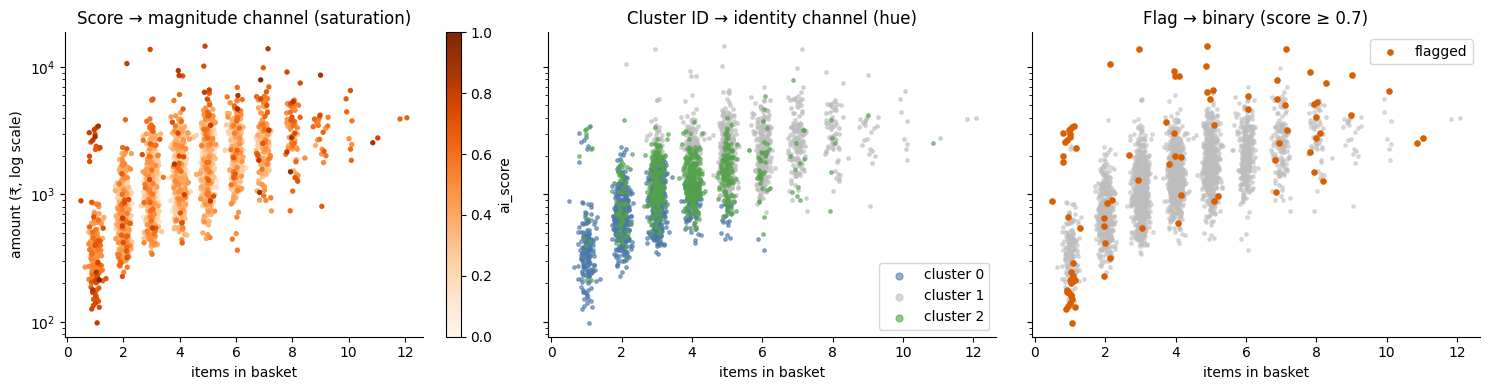

Flagged: 89 | just below the threshold (0.65–0.70): 42 items, 6 of them real anomalies. A binary flag draws these exactly like a score of 0.05.


In [4]:
THR = 0.70
tx["ai_flag"] = (tx.ai_score >= THR).astype(int)
tx["cluster"] = KMeans(3, n_init=10, random_state=0).fit_predict(X[:, [0, 1, 3]])
abstraction = pd.DataFrame({
    "attribute": ["tx_id", "category", "items", "amount", "hour", "ai_score", "cluster", "ai_flag"],
    "type": ["key", "categorical", "quantitative", "quantitative", "cyclic (temporal)", "quantitative (derived)", "categorical (derived)", "binary (derived)"],
    "suitable channel": ["none (label on demand)", "hue / shape", "position", "position", "position on a circle or line", "position, size, saturation", "hue / shape", "hue (sparingly)"]})
display(abstraction)

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
jit = rng.normal(0, .12, N)
o = np.argsort(tx.ai_score.values)
sc = ax[0].scatter(tx["items"].values[o] + jit[o], tx.amount.values[o], c=tx.ai_score.values[o], cmap="Oranges", s=8, vmin=0, vmax=1)
fig.colorbar(sc, ax=ax[0], label="ai_score"); ax[0].set_title("Score → magnitude channel (saturation)")
for k_, col in zip(range(3), [BLUE, GREY, "#54a24b"]):
    m = tx.cluster == k_
    ax[1].scatter(tx["items"][m] + jit[m], tx.amount[m], s=6, color=col, alpha=.6, label=f"cluster {k_}")
ax[1].legend(markerscale=2); ax[1].set_title("Cluster ID → identity channel (hue)")
ax[2].scatter(tx["items"] + jit, tx.amount, s=6, color=GREY, alpha=.5)
f = tx.ai_flag == 1
ax[2].scatter(tx["items"][f] + jit[f], tx.amount[f], s=14, color=ACCENT, label="flagged")
ax[2].legend(); ax[2].set_title(f"Flag → binary (score ≥ {THR})")
for a_ in ax: a_.set_xlabel("items in basket"); a_.set_yscale("log")
ax[0].set_ylabel("amount (₹, log scale)")
plt.tight_layout(); plt.show()

near = tx[(tx.ai_score >= THR - 0.05) & (tx.ai_score < THR)]
print(f"Flagged: {f.sum()} | just below the threshold ({THR - 0.05:.2f}–{THR:.2f}): {len(near)} items, "
      f"{near.is_anomaly.sum()} of them real anomalies. A binary flag draws these exactly like a score of 0.05.")

## 3 · What is a pattern? What does perception contribute?

Munzner §3.5 (targets): a **trend** is a high-level characterization (e.g. an increase over time); **outliers** (anomalies, novelties, deviants, surprises) are items that do not fit the pattern; **features** are task-dependent structures of interest. For attributes the targets are *distribution, extremes, dependency, correlation, similarity*.

Ware (Ch. 6): pattern perception sits between feature detection and object recognition. Gestalt proximity and similarity make nearby or alike marks group, which is how we see clusters (G6.1: place related symbols close together). Munzner §5.5.5: containment is the strongest grouping cue, so a drawn outline is a strong claim.

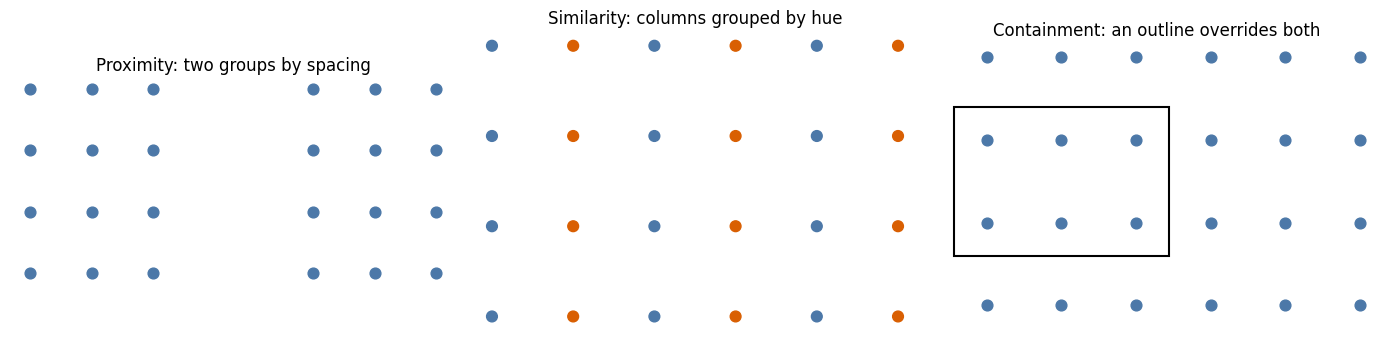

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
g = np.array([(x, y) for x in range(6) for y in range(4)], float)
shift = np.where(g[:, 0] >= 3, 1.6, 0)
ax[0].scatter(g[:, 0] + shift, g[:, 1], s=60, color=BLUE); ax[0].set_title("Proximity: two groups by spacing")
ax[1].scatter(g[:, 0] * 0.9, g[:, 1], s=60, color=[ACCENT if x % 2 else BLUE for x in g[:, 0]]); ax[1].set_title("Similarity: columns grouped by hue")
ax[2].scatter(g[:, 0] * 0.9, g[:, 1], s=60, color=BLUE)
ax[2].add_patch(plt.Rectangle((-0.4, 0.6), 2.6, 1.8, fill=False, ec="k", lw=1.5)); ax[2].set_title("Containment: an outline overrides both")
for a_ in ax: a_.set_xticks([]); a_.set_yticks([]); a_.set_aspect("equal"); [s.set_visible(False) for s in a_.spines.values()]
plt.tight_layout(); plt.show()

## 4 · Histograms: the first view of a distribution (Wilke Ch. 7)

A histogram counts items in bins; **the shape depends on the bin width.** Too narrow: noisy and peaky. Too wide: real features (a dip, a small far tail) vanish. For anomalies: isolated, sparsely filled bins far from the main mass are the visual signature of outliers, **and the bin width decides whether you see them.** A histogram is itself a parameterised algorithm.

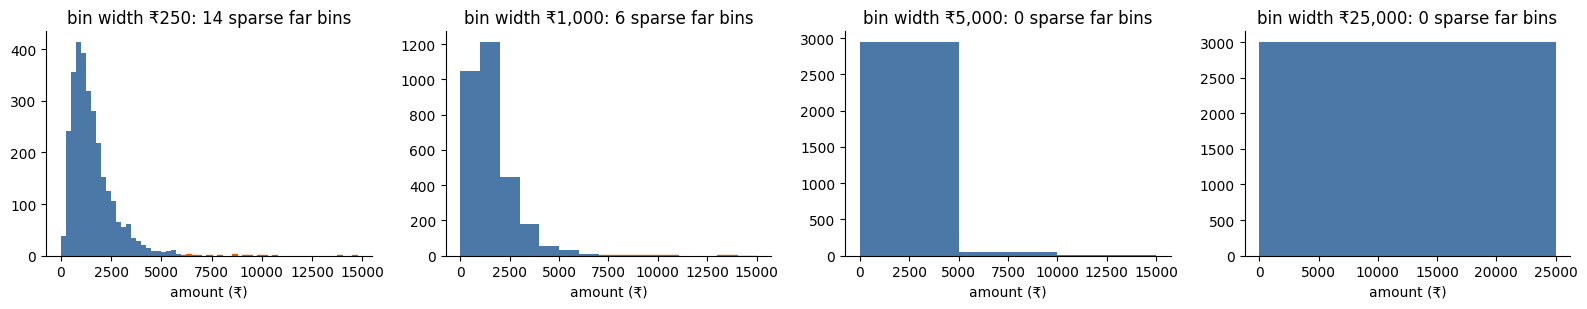

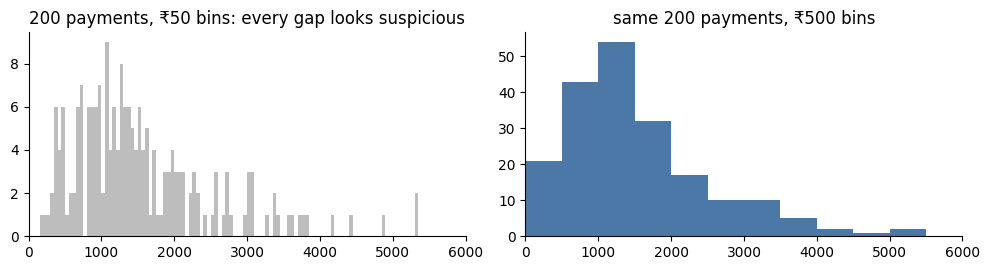

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a_, w_ in zip(ax, [250, 1000, 5000, 25000]):
    cnt, edges, bars = a_.hist(tx.amount, bins=np.arange(0, tx.amount.max() + w_, w_), color=BLUE)
    lonely = (cnt > 0) & (cnt <= 3) & (edges[:-1] > tx.amount.quantile(.99))
    for bar, l_ in zip(bars, lonely):
        if l_: bar.set_color(ACCENT)
    a_.set_title(f"bin width ₹{w_:,}: {lonely.sum()} sparse far bins"); a_.set_xlabel("amount (₹)")
plt.tight_layout(); plt.show()

small = tx.amount.sample(200, random_state=3)
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))
ax[0].hist(small, bins=np.arange(0, 6000, 50), color=GREY); ax[0].set_title("200 payments, ₹50 bins: every gap looks suspicious"); ax[0].set_xlim(0, 6000)
ax[1].hist(small, bins=np.arange(0, 6000, 500), color=BLUE); ax[1].set_title("same 200 payments, ₹500 bins"); ax[1].set_xlim(0, 6000)
plt.tight_layout(); plt.show()

## 5 · Density plots (Wilke Ch. 7)

A kernel density estimate puts a small smooth bump at each data point and adds them up. The **bandwidth** plays the role of bin width. A density curve is an *estimate*, not the data, and it **can extend into regions where no data exist or could exist**: read the tails with care.

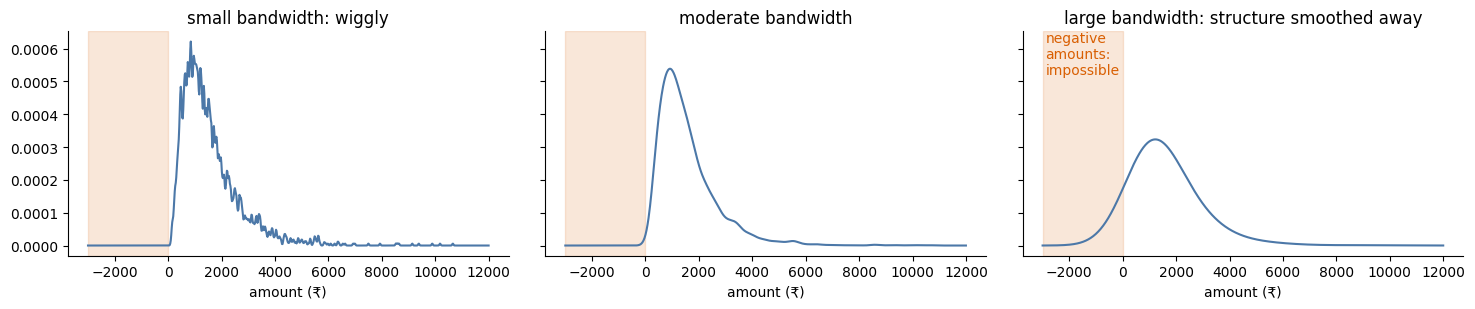

Density mass the large-bandwidth curve puts on NEGATIVE amounts: 10.9%


In [7]:
x = np.linspace(-3000, 12000, 800)
amt = tx.amount[tx.amount < 12000]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for a_, (bw, lab) in zip(ax, [(0.02, "small bandwidth: wiggly"), (0.15, "moderate bandwidth"), (0.8, "large bandwidth: structure smoothed away")]):
    a_.plot(x, stats.gaussian_kde(amt, bw_method=bw)(x), color=BLUE)
    a_.axvspan(-3000, 0, color=ACCENT, alpha=.15); a_.set_title(lab); a_.set_xlabel("amount (₹)")
ax[2].text(-2900, ax[2].get_ylim()[1] * .8, "negative\namounts:\nimpossible", color=ACCENT)
plt.tight_layout(); plt.show()
kde = stats.gaussian_kde(amt, bw_method=0.8)
print(f"Density mass the large-bandwidth curve puts on NEGATIVE amounts: {kde.integrate_box_1d(-1e6, 0):.1%}")

## 6 · Look at the distribution of AI scores before choosing a cut-off

A **clearly separated tail** suggests a natural threshold; a **smooth continuum** means any cut-off is a judgement call. Compare flagged / unflagged (or true / normal) groups with **overlapping density plots**, not stacked histograms, which are hard to compare (Wilke Ch. 7).

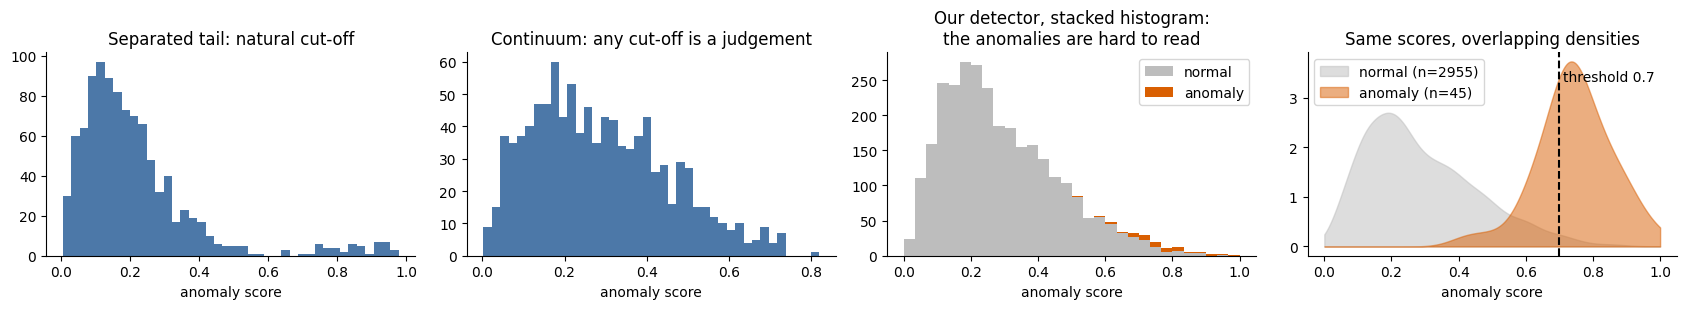

In [8]:
rs = np.random.default_rng(1)
sep = np.r_[rs.beta(2, 9, 950), rs.beta(14, 3, 50)]
cont = rs.beta(2, 5, 1000)
fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
ax[0].hist(sep, bins=40, color=BLUE); ax[0].set_title("Separated tail: natural cut-off")
ax[1].hist(cont, bins=40, color=BLUE); ax[1].set_title("Continuum: any cut-off is a judgement")
s_norm, s_anom = tx.ai_score[tx.is_anomaly == 0], tx.ai_score[tx.is_anomaly == 1]
ax[2].hist([s_norm, s_anom], bins=30, stacked=True, color=[GREY, ACCENT], label=["normal", "anomaly"]); ax[2].legend()
ax[2].set_title("Our detector, stacked histogram:\nthe anomalies are hard to read")
xs = np.linspace(0, 1, 300)
for s_, col, lab in [(s_norm, GREY, "normal"), (s_anom, ACCENT, "anomaly")]:
    ax[3].fill_between(xs, stats.gaussian_kde(s_)(xs), color=col, alpha=.5, label=f"{lab} (n={len(s_)})")
ax[3].axvline(THR, color="k", ls="--"); ax[3].text(THR + .01, ax[3].get_ylim()[1] * .85, f"threshold {THR}")
ax[3].legend(); ax[3].set_title("Same scores, overlapping densities")
for a_ in ax: a_.set_xlabel("anomaly score")
plt.tight_layout(); plt.show()

## 7 · Visualizing associations: scatterplots (Wilke Ch. 12)

One dot per item shows trends, clusters and isolated points **before any algorithm runs**. A third variable can go on colour or shape. Heavy overplotting hides structure: use transparency or smaller marks.

The type-B anomalies (₹3,000–5,000 for one item) are **invisible in the histogram of amount** but obvious in the scatter of amount against items.

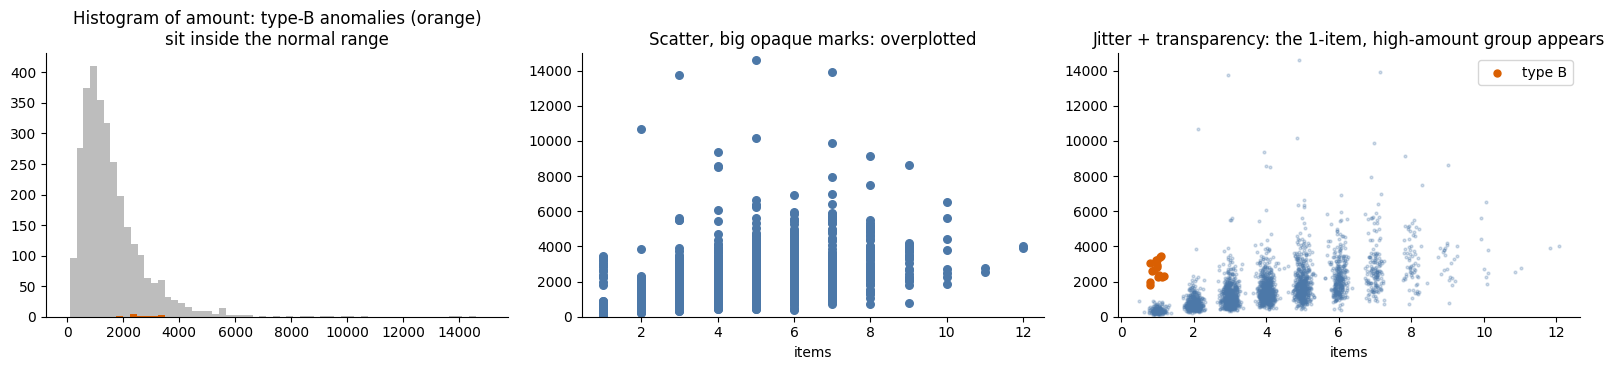

In [9]:
B = tx.kind.str.startswith("B")
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(tx.amount[tx.amount < 15000], bins=60, color=GREY)
ax[0].hist(tx.amount[B], bins=60, range=(0, 15000), color=ACCENT); ax[0].set_title("Histogram of amount: type-B anomalies (orange)\nsit inside the normal range")
ax[1].scatter(tx["items"], tx.amount, s=30, color=BLUE); ax[1].set_title("Scatter, big opaque marks: overplotted")
ax[2].scatter(tx["items"] + jit, tx.amount, s=4, alpha=.25, color=BLUE)
ax[2].scatter(tx["items"][B] + jit[B], tx.amount[B], s=25, color=ACCENT, label="type B")
ax[2].set_title("Jitter + transparency: the 1-item, high-amount group appears"); ax[2].legend()
for a_ in ax[1:]: a_.set_ylim(0, 15000); a_.set_xlabel("items")
plt.tight_layout(); plt.show()

## 8 · Correlation and correlograms (Wilke Ch. 12)

r summarizes the strength of a **linear** association in one number; a correlogram shows all pairs. Wilke's caution: a correlogram shows **derived quantities, not the data**. A single r cannot reveal curves, clusters or outliers, and the same lesson applies to anomaly scores.

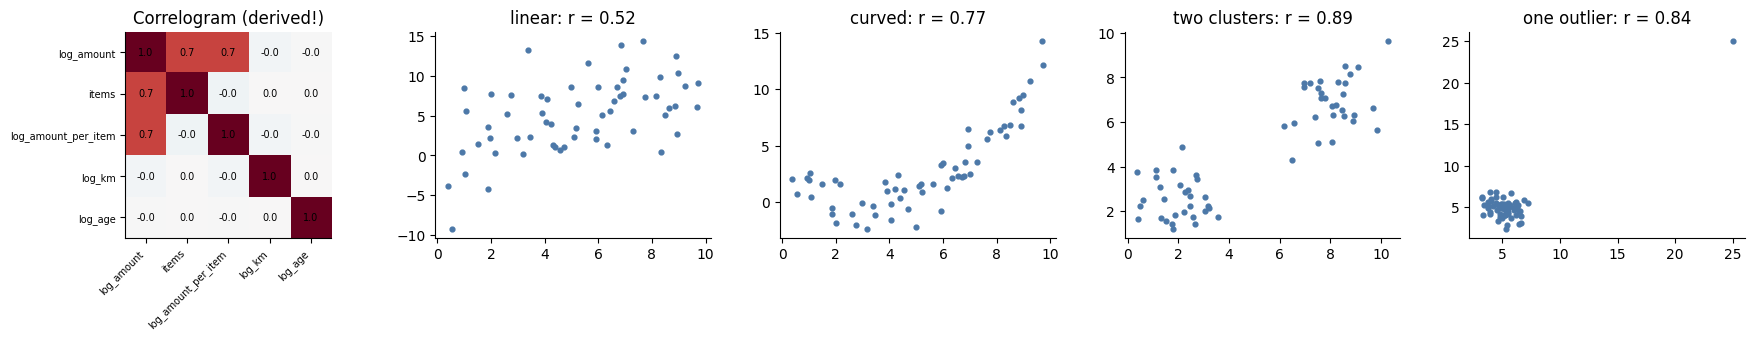

Similar r, completely different structure: the 'one outlier' panel has r ≈ 0.8 driven by a single point.


In [10]:
num = features(tx)[["log_amount", "items", "log_amount_per_item", "log_km", "log_age"]]
cm = num.corr()
rs = np.random.default_rng(2)
x1 = rs.uniform(0, 10, 60)
sets = {"linear": (x1, x1 + rs.normal(0, 4, 60)),
        "curved": (x1, (x1 - 3) ** 2 / 4 + rs.normal(0, 1.5, 60)),
        "two clusters": (np.r_[rs.normal(2, .8, 30), rs.normal(8, .8, 30)], np.r_[rs.normal(3, 1, 30), rs.normal(7, 1, 30)]),
        "one outlier": (np.r_[rs.normal(5, 1, 59), 25], np.r_[rs.normal(5, 1, 59), 25])}
fig, ax = plt.subplots(1, 5, figsize=(18, 3.4))
im = ax[0].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(cm))); ax[0].set_xticklabels(cm.columns, rotation=45, ha="right", fontsize=7)
ax[0].set_yticks(range(len(cm))); ax[0].set_yticklabels(cm.columns, fontsize=7); ax[0].set_title("Correlogram (derived!)")
for i in range(len(cm)):
    for j in range(len(cm)): ax[0].text(j, i, f"{cm.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
for a_, (k_, (xx, yy)) in zip(ax[1:], sets.items()):
    a_.scatter(xx, yy, s=12, color=BLUE); a_.set_title(f"{k_}: r = {np.corrcoef(xx, yy)[0, 1]:.2f}")
plt.tight_layout(); plt.show()
print("Similar r, completely different structure: the 'one outlier' panel has r ≈ 0.8 driven by a single point.")

## 9 · Dimension reduction: PCA (Wilke Ch. 12)

PCA rotates the data to new axes ordered by how much variation they capture. The first two components often show **groups as clusters**, and items far from every group are **candidate outliers**. Caveat: components mix the original variables, so they are harder to interpret; look at the loadings.

explained variance: [0.28 0.19]


,PC1,PC2
log_amount,0.71,-0.01
items,0.49,0.04
log_amount_per_item,0.49,-0.06
log_km,-0.03,0.00
hour_sin,0.01,0.70
hour_cos,-0.02,-0.70
log_age,0.00,0.06


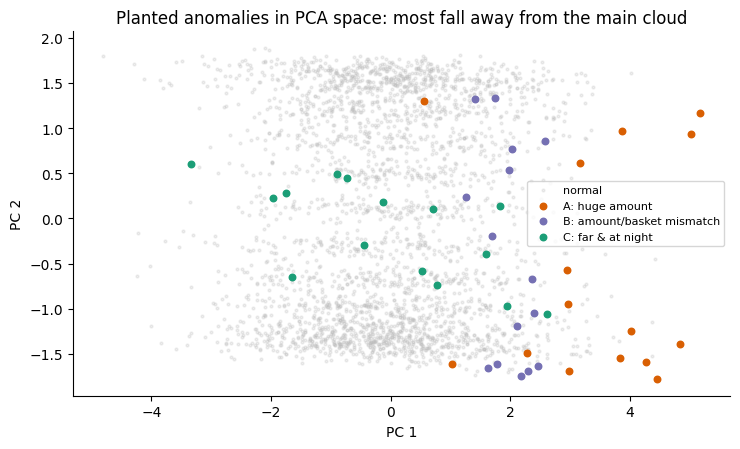

In [11]:
pca = PCA(n_components=2).fit(X); P = pca.transform(X)
print("explained variance:", pca.explained_variance_ratio_.round(2))
display(pd.DataFrame(pca.components_.T, index=features(tx).columns, columns=["PC1", "PC2"]).round(2))
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(P[:, 0], P[:, 1], s=4, alpha=.25, color=GREY, label="normal")
for k_, col in zip(sorted(tx.kind.unique())[:3], [ACCENT, "#7570b3", "#1b9e77"]):
    m = (tx.kind == k_).values
    ax.scatter(P[m, 0], P[m, 1], s=22, color=col, label=k_)
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=8); ax.set_title("Planted anomalies in PCA space: most fall away from the main cloud")
plt.tight_layout(); plt.show()

## 10 · Automated trend detection: fit a model, look at the residuals

A trend detector fits a model (a line, a smoother, a seasonal baseline); **the residuals show what it does not explain**, and large residuals are anomaly candidates. Synthetic series: 120 days of daily transaction counts with a trend, a weekly cycle, and three planted odd days.

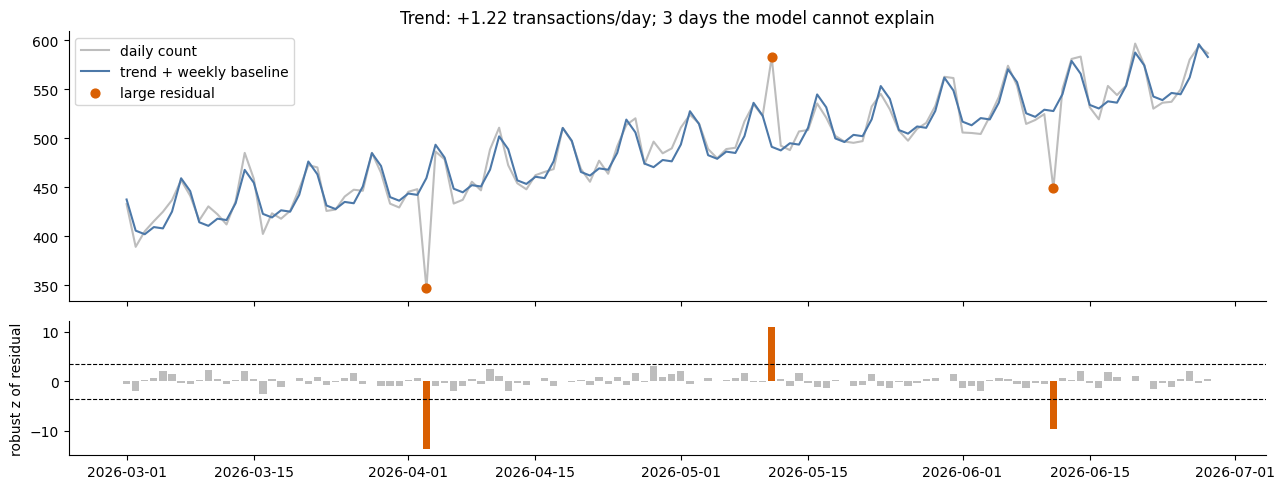

Odd days: ['2026-04-03', '2026-05-11', '2026-06-11']


In [12]:
rs = np.random.default_rng(5)
days = pd.date_range("2026-03-01", periods=120, freq="D")
t = np.arange(120)
weekly = np.array([0, 5, 8, 10, 30, 55, 40])[days.day_of_week]
y = 400 + 1.2 * t + weekly + rs.normal(0, 9, 120)
y[[33, 71, 102]] += [-120, 95, -85]                                          # outage, promo spike, data gap
dow = pd.get_dummies(days.day_of_week, drop_first=True).values.astype(float)
Xd = np.c_[np.ones(120), t, dow]
beta = np.linalg.lstsq(Xd, y, rcond=None)[0]
fit = Xd @ beta; res = y - fit
z = (res - np.median(res)) / (1.4826 * stats.median_abs_deviation(res))     # robust z of residuals
odd = np.where(np.abs(z) > 3.5)[0]
fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True, height_ratios=[2, 1])
ax[0].plot(days, y, color=GREY, label="daily count"); ax[0].plot(days, fit, color=BLUE, label="trend + weekly baseline")
ax[0].scatter(days[odd], y[odd], color=ACCENT, zorder=3, s=40, label="large residual"); ax[0].legend(); ax[0].set_title(f"Trend: +{beta[1]:.2f} transactions/day; {len(odd)} days the model cannot explain")
ax[1].bar(days, z, color=[ACCENT if i in odd else GREY for i in range(120)]); ax[1].axhline(3.5, ls="--", color="k", lw=.8); ax[1].axhline(-3.5, ls="--", color="k", lw=.8)
ax[1].set_ylabel("robust z of residual")
plt.tight_layout(); plt.show()
print("Odd days:", [str(days[i].date()) for i in odd])

## 11 · Automated cluster detection

**k-means** alternates *assign* (each point to its nearest centre) and *update* (move each centre to the mean of its points). **k is chosen by the user, and every point still gets a label**, including outliers.

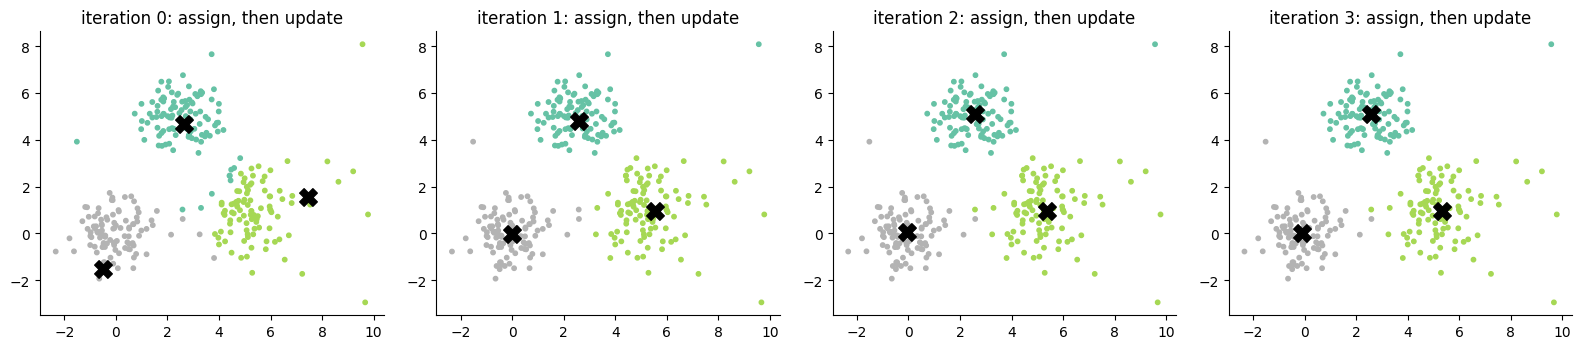

In [13]:
Xb, yb = make_blobs(n_samples=300, centers=[(0, 0), (5, 1), (2.5, 5)], cluster_std=[.8, .9, .8], random_state=3)
Xb = np.r_[Xb, np.random.default_rng(4).uniform([-4, -4], [10, 9], (10, 2))]           # 10 scattered outliers
cent = Xb[[0, 1, 2]].copy()
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for it, a_ in enumerate(ax):
    lab = np.argmin(((Xb[:, None, :] - cent[None]) ** 2).sum(-1), axis=1)
    a_.scatter(Xb[:, 0], Xb[:, 1], c=lab, cmap="Set2", s=10); a_.scatter(cent[:, 0], cent[:, 1], marker="X", s=160, color="k")
    a_.set_title(f"iteration {it}: assign, then update")
    cent = np.array([Xb[lab == k_].mean(0) for k_ in range(3)])
plt.tight_layout(); plt.show()

### Common clustering approaches give different answers
| Approach | Key idea | Outliers |
|---|---|---|
| k-means | needs k; compact round groups | **forced into a cluster** |
| DBSCAN (Ester et al. 1996) | dense regions of any shape | labelled **noise**: a built-in outlier signal |
| Hierarchical | tree of merges; choose the level | end up as small late-merging branches |

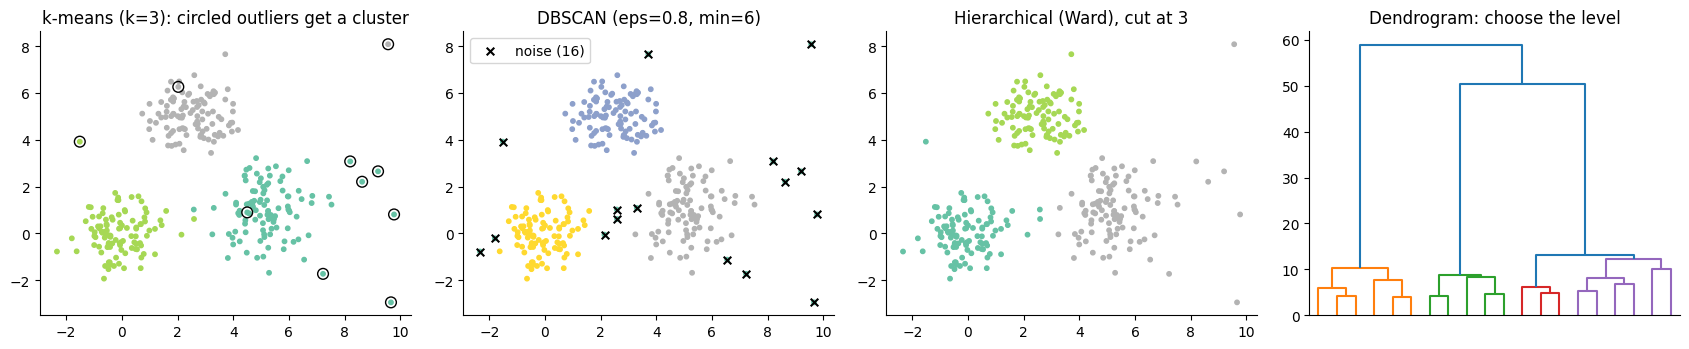

Outliers flagged as noise by DBSCAN: 8 of 10 | by k-means: 0 of 10 (every point gets a label)


In [14]:
km_lab = KMeans(3, n_init=10, random_state=0).fit_predict(Xb)
db_lab = DBSCAN(eps=0.8, min_samples=6).fit_predict(Xb)
Lk = linkage(Xb, "ward"); hc_lab = fcluster(Lk, 3, "maxclust")
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].scatter(Xb[:, 0], Xb[:, 1], c=km_lab, cmap="Set2", s=10); ax[0].scatter(Xb[300:, 0], Xb[300:, 1], s=60, facecolors="none", edgecolors="k")
ax[0].set_title("k-means (k=3): circled outliers get a cluster")
ax[1].scatter(Xb[:, 0], Xb[:, 1], c=np.where(db_lab < 0, -1, db_lab), cmap="Set2", s=10)
ax[1].scatter(Xb[db_lab < 0, 0], Xb[db_lab < 0, 1], s=30, color="k", marker="x", label=f"noise ({(db_lab < 0).sum()})"); ax[1].legend()
ax[1].set_title("DBSCAN (eps=0.8, min=6)")
ax[2].scatter(Xb[:, 0], Xb[:, 1], c=hc_lab, cmap="Set2", s=10); ax[2].set_title("Hierarchical (Ward), cut at 3")
dendrogram(Lk, ax=ax[3], truncate_mode="lastp", p=20, no_labels=True, color_threshold=Lk[-3, 2]); ax[3].set_title("Dendrogram: choose the level")
plt.tight_layout(); plt.show()
print("Outliers flagged as noise by DBSCAN:", int((db_lab[300:] < 0).sum()), "of 10 | by k-means: 0 of 10 (every point gets a label)")

### Showing detected clusters honestly (Munzner §5.5.5, Wilke Ch. 12)
* Cluster ID → **hue or shape**; keep position for the data's own coordinates.
* Hard outlines (containment) imply a crisp boundary the data may not have; use sparingly.
* Let the viewer see the raw points beneath the labels.
* **State the algorithm and parameters, and show stability** under other settings.

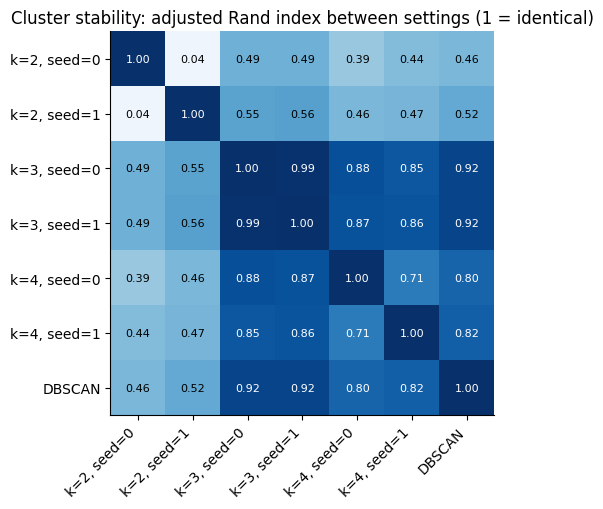

In [15]:
settings = [(k_, s_) for k_ in (2, 3, 4) for s_ in (0, 1)]
labs = {f"k={k_}, seed={s_}": KMeans(k_, n_init=1, random_state=s_).fit_predict(Xb) for k_, s_ in settings}
labs["DBSCAN"] = db_lab
names = list(labs)
ari = pd.DataFrame([[adjusted_rand_score(labs[i], labs[j]) for j in names] for i in names], index=names, columns=names).round(2)
fig, ax = plt.subplots(figsize=(7, 5.2))
im = ax.imshow(ari, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)): ax.text(j, i, f"{ari.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w" if ari.iloc[i, j] > .6 else "k")
ax.set_title("Cluster stability: adjusted Rand index between settings (1 = identical)")
plt.tight_layout(); plt.show()

## 12 · Outlier identification

* **Boxplot rule** (Wilke Ch. 9): points beyond 1.5 × IQR from the box are drawn individually.
* **z-score rule**: flag |z| above a cut-off such as 3.

The z-score uses the mean and SD, **which the outliers themselves inflate** (masking). The IQR fences are robust.

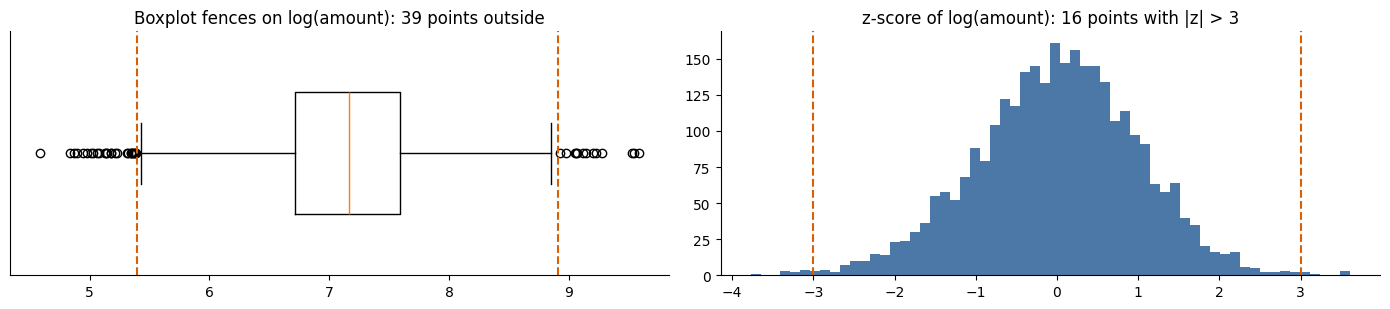

In [16]:
la = np.log(tx.amount)
q1, q3 = la.quantile([.25, .75]); iqr = q3 - q1
lo_f, hi_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
zs = (la - la.mean()) / la.std()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
ax[0].boxplot(la, orientation="horizontal", widths=.5); ax[0].axvline(lo_f, ls="--", color=ACCENT); ax[0].axvline(hi_f, ls="--", color=ACCENT)
ax[0].set_title(f"Boxplot fences on log(amount): {((la < lo_f) | (la > hi_f)).sum()} points outside"); ax[0].set_yticks([])
ax[1].hist(zs, bins=60, color=BLUE); ax[1].axvline(3, color=ACCENT, ls="--"); ax[1].axvline(-3, color=ACCENT, ls="--")
ax[1].set_title(f"z-score of log(amount): {(zs.abs() > 3).sum()} points with |z| > 3")
plt.tight_layout(); plt.show()

### Detector families compared on the same data
| Family | Idea | Strength | Weakness |
|---|---|---|---|
| z-score | distance from the mean in SDs | simple, fast | mean and SD distorted by the outliers |
| IQR fences | beyond Q1 − 1.5 IQR or Q3 + 1.5 IQR | robust | one variable at a time |
| Distance / density (LOF) | sparser than its neighbours | several variables | needs a distance; scales poorly |
| Isolation (Isolation Forest) | few random splits isolate it | fast on large data | scores need careful thresholding |
| Reconstruction (here: PCA) | normal data is reconstructed well | complex normal behaviour | hard to explain why |

Each detector below flags its **top 45** items (the true number of anomalies), so the comparison is fair. Because we know the truth, we can see **which kind of anomaly each family can see.**

In [17]:
scores = {
    "z-score (amount)": np.abs(zs.values),
    "IQR distance (amount)": np.maximum(lo_f - la, la - hi_f).values,
    "LOF (all features)": -LocalOutlierFactor(n_neighbors=35).fit(X).negative_outlier_factor_,
    "Isolation Forest": tx.ai_score.values,
    "PCA reconstruction": ((X - PCA(3).fit(X).inverse_transform(PCA(3).fit(X).transform(X))) ** 2).sum(1),
}
rows = []
for name, s_ in scores.items():
    top = np.argsort(-s_)[:45]
    hit = tx.iloc[top]
    rows.append({"detector": name, "precision@45": round(hit.is_anomaly.mean(), 2),
                 **{k_[:1] + " caught": int((hit.kind == k_).sum()) for k_ in sorted(tx.kind.unique())[:3]}})
display(pd.DataFrame(rows).set_index("detector"))
print("Univariate rules on amount only see type A. Type B (normal values, abnormal combination) needs a multivariate detector.")

,precision@45,A caught,B caught,C caught
detector,,,,
z-score (amount),0.20,8,0,1
IQR distance (amount),0.20,8,0,1
LOF (all features),0.49,8,12,2
Isolation Forest,0.42,6,6,7
PCA reconstruction,0.18,0,0,8


Univariate rules on amount only see type A. Type B (normal values, abnormal combination) needs a multivariate detector.


## 13 · Anomaly detection (Chandola, Banerjee & Kumar 2009)

Anomaly detection finds items or patterns that deviate from expected behaviour.

| Setting | Learns from | Example |
|---|---|---|
| Supervised | labelled anomalies and normals | classifier trained on past confirmed fraud |
| Semi-supervised | normal data only | model of normal sensor behaviour |
| Unsupervised | no labels | Isolation Forest, LOF (this notebook) |

Most detectors output a **score per item**; a **threshold** turns the score into an alert. The score is a **derived attribute** (Munzner): visualize and examine it, don't only threshold it.

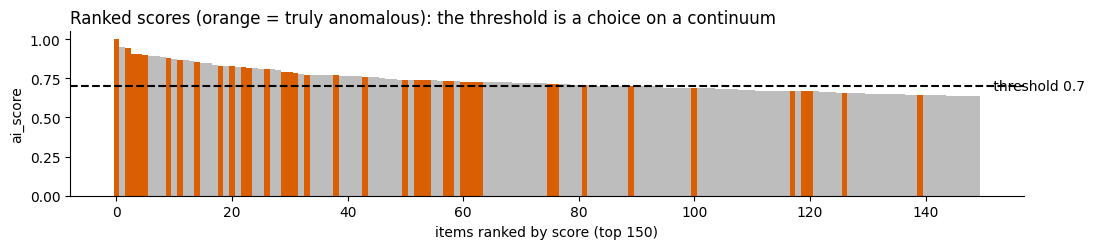

In [18]:
fig, ax = plt.subplots(figsize=(11, 2.6))
o = np.argsort(-tx.ai_score.values)[:150]
ax.bar(range(150), tx.ai_score.values[o], color=[ACCENT if v else GREY for v in tx.is_anomaly.values[o]], width=1)
ax.axhline(THR, color="k", ls="--"); ax.text(151, THR, f" threshold {THR}", va="center")
ax.set_xlabel("items ranked by score (top 150)"); ax.set_ylabel("ai_score")
ax.set_title("Ranked scores (orange = truly anomalous): the threshold is a choice on a continuum", loc="left")
plt.tight_layout(); plt.show()

## 14 · Types of anomalies: point, contextual, collective

Synthetic series: hourly temperature of a machine for 21 days, with a daily cycle (warm by day, cool at night). Three anomalies are planted:

| Type | What is abnormal | Needs to know | How to show it |
|---|---|---|---|
| **Point** | a single instance | the overall distribution | highlight one mark |
| **Contextual** | an instance in its context (35 °F in summer) | context attributes (time, place) | show the context beside the mark |
| **Collective** | a group of instances together (a flat-lining sensor) | the sequence or relationships | highlight the whole span |

global |z| > 3.5: 1 | contextual |z| > 5 (and not global): 3 | 6-hour windows with SD ≈ 0: 2


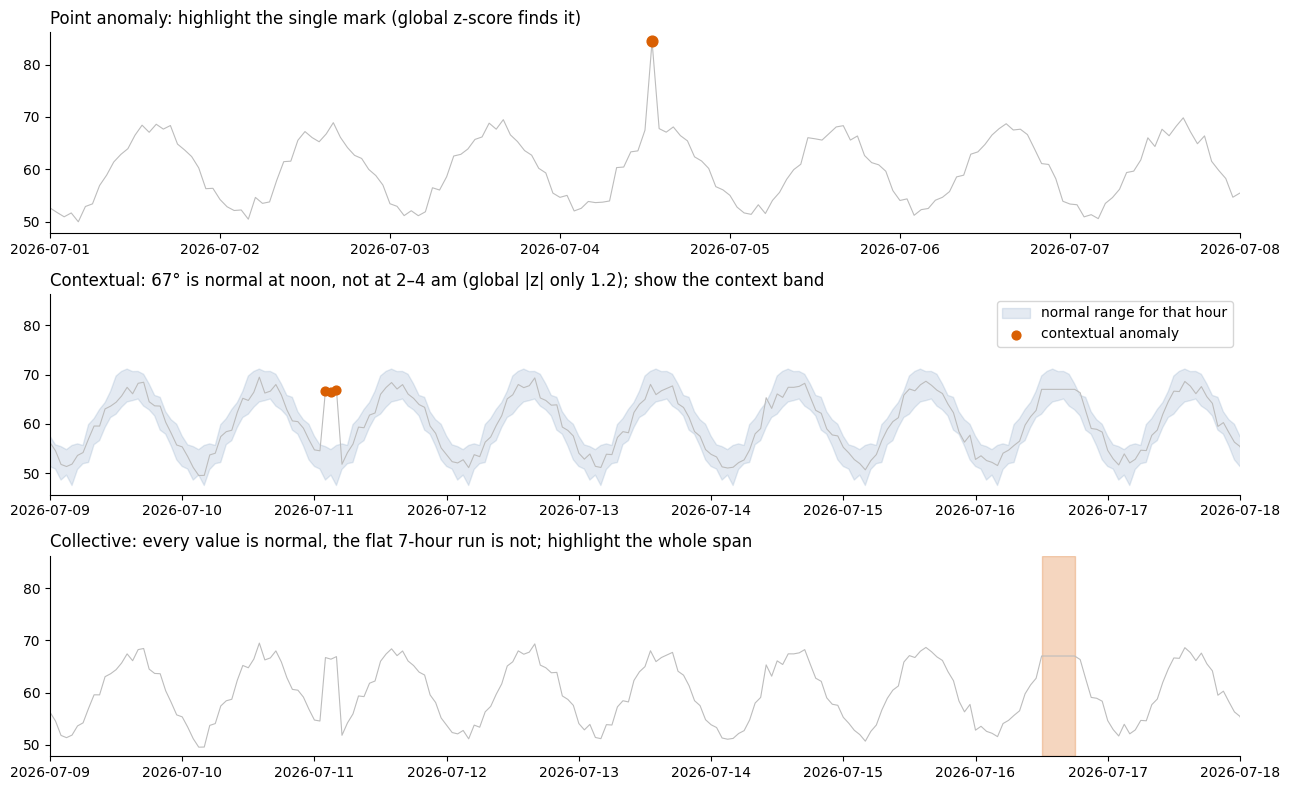

In [19]:
rs = np.random.default_rng(8)
ts = pd.date_range("2026-07-01", periods=21 * 24, freq="h")
hr = ts.hour.values
temp = 60 + 8 * np.sin(2 * np.pi * (hr - 9) / 24) + rs.normal(0, 1.0, len(ts))
p_i = 3 * 24 + 13; temp[p_i] += 17                                            # point: a spike
c_i = np.arange(10 * 24 + 2, 10 * 24 + 5); temp[c_i] = 67 + rs.normal(0, .4, 3)   # contextual: daytime level at 2-4 am
k_i = np.arange(15 * 24 + 12, 15 * 24 + 19); temp[k_i] = 67.0                 # collective: sensor stuck for 7 h (each value normal)
m = pd.DataFrame({"ts": ts, "hour": hr, "temp": temp})

m["z_global"] = (m.temp - m.temp.mean()) / m.temp.std()
base = m.groupby("hour").temp.agg(["median", lambda s: 1.4826 * stats.median_abs_deviation(s)]); base.columns = ["h_med", "h_mad"]
m = m.join(base, on="hour"); m["z_context"] = (m.temp - m.h_med) / m.h_mad
m["roll_sd"] = m.temp.rolling(6).std()
point = m.index[m.z_global.abs() > 3.5]
context = m.index[(m.z_context.abs() > 5) & (m.z_global.abs() <= 3.5)]
collective = m.index[m.roll_sd < 0.05]
print("global |z| > 3.5:", len(point), "| contextual |z| > 5 (and not global):", len(context), "| 6-hour windows with SD ≈ 0:", len(collective))

fig, ax = plt.subplots(3, 1, figsize=(13, 8))
for a_ in ax: a_.plot(m.ts, m.temp, color=GREY, lw=.8)
ax[0].scatter(m.ts[point], m.temp[point], color=ACCENT, s=60, zorder=3); ax[0].set_title("Point anomaly: highlight the single mark (global z-score finds it)", loc="left")
ax[1].fill_between(m.ts, m.h_med - 3 * m.h_mad, m.h_med + 3 * m.h_mad, color=BLUE, alpha=.15, label="normal range for that hour")
ax[1].scatter(m.ts[context], m.temp[context], color=ACCENT, s=40, zorder=3, label="contextual anomaly"); ax[1].legend(loc="upper right")
ax[1].set_title(f"Contextual: {m.temp[context].mean():.0f}° is normal at noon, not at 2–4 am (global |z| only {m.z_global[context].abs().max():.1f}); show the context band", loc="left")
s0, s1 = m.ts[collective.min() - 5], m.ts[collective.max()]
ax[2].axvspan(s0, s1, color=ACCENT, alpha=.25); ax[2].set_title("Collective: every value is normal, the flat 7-hour run is not; highlight the whole span", loc="left")
ax[0].set_xlim(m.ts[0], m.ts[7 * 24])
for a_ in ax[1:]: a_.set_xlim(m.ts[8 * 24], m.ts[17 * 24])
plt.tight_layout(); plt.show()

## 15 · Visual highlighting of AI-detected anomalies (Ware Ch. 5; Munzner §5.5.4)

Highlighting must make flagged items easy to find **without destroying the rest of the picture**.
* **G5.6**: for maximum pop-out a symbol should be the **only** object distinctive on a feature channel.
* **G5.7–G5.8**: use a positively asymmetric cue (add, don't remove), on the channel **used least elsewhere**.
* Munzner: for a single distinct target, pop-out time does not depend on the number of distractors. **Conjunctions** (red *and* circle among red squares and grey circles) do not pop out.

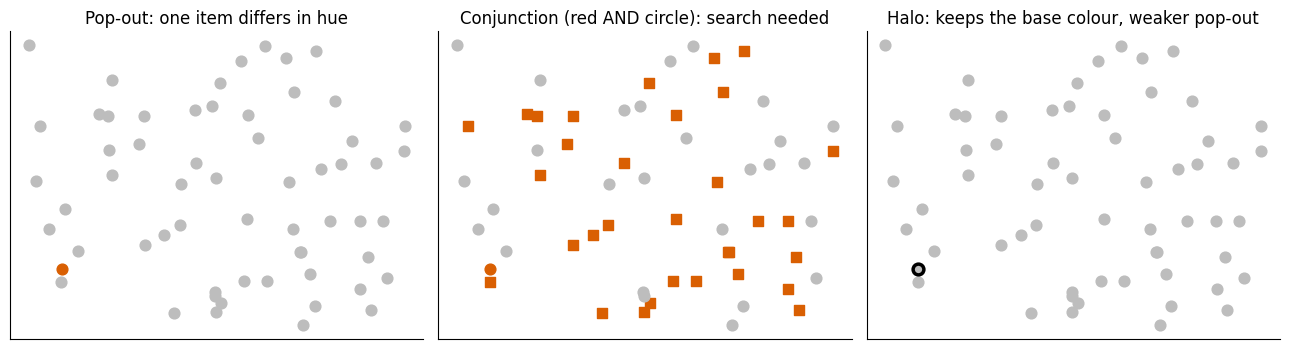

In [20]:
rs = np.random.default_rng(3)
pts = rs.uniform(0, 1, (60, 2))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].scatter(pts[1:, 0], pts[1:, 1], color=GREY, s=60); ax[0].scatter(*pts[0], color=ACCENT, s=60); ax[0].set_title("Pop-out: one item differs in hue")
mk = rs.random(59) < .5
ax[1].scatter(pts[1:, 0][mk], pts[1:, 1][mk], color=ACCENT, marker="s", s=55); ax[1].scatter(pts[1:, 0][~mk], pts[1:, 1][~mk], color=GREY, s=60)
ax[1].scatter(*pts[0], color=ACCENT, s=60); ax[1].set_title("Conjunction (red AND circle): search needed")
ax[2].scatter(pts[:, 0], pts[:, 1], color=GREY, s=60); ax[2].scatter(pts[0, 0], pts[0, 1], color=GREY, s=60, edgecolors="k", linewidths=2.5)
ax[2].set_title("Halo: keeps the base colour, weaker pop-out")
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()

### Choosing a channel for highlighting
| Channel | Pop-out | Caution |
|---|---|---|
| Hue | strong when only flagged items differ | may already encode a category; colour-deficient viewers |
| Size | strong | **changes the apparent magnitude of the data** |
| Shape | good for a few items | many shapes are hard to tell apart |
| Outline / halo | moderate; keeps the base colour | less visible on dense plots |
| Motion / blink | very strong (G5.9) | distracting; keep it subtle |
| Position / rank list | strong (magnitude channel) | separates items from their context |

Below, the same 25 flagged transactions with four channels. Note that **hue is already used for category**, so a hue highlight conflicts with it (G5.8: use the channel used least elsewhere).

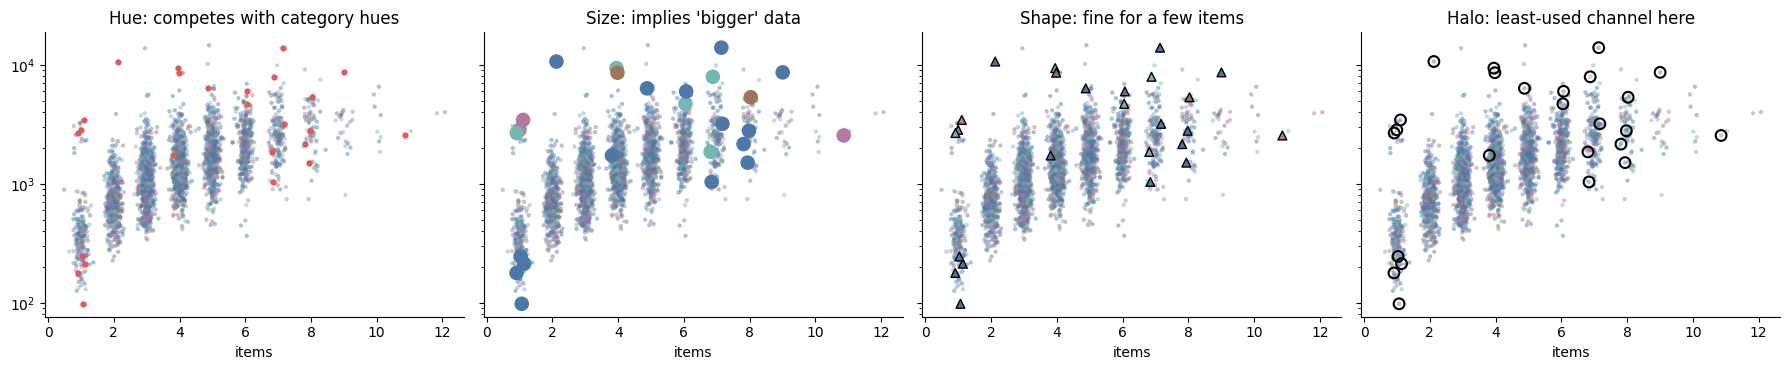

In [21]:
top25 = tx.nlargest(25, "ai_score").index
catcol = dict(zip(["Grocery", "Electronics", "Fashion", "Travel"], ["#4c78a8", "#72b7b2", "#b279a2", "#9d755d"]))
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for a_ in ax:
    a_.scatter(tx["items"] + jit, tx.amount, s=5, c=tx.category.map(catcol), alpha=.35)
    a_.set_yscale("log"); a_.set_xlabel("items")
h = tx.loc[top25]
ax[0].scatter(h["items"] + jit[top25], h.amount, s=12, color="#e45756"); ax[0].set_title("Hue: competes with category hues")
ax[1].scatter(h["items"] + jit[top25], h.amount, s=90, c=h.category.map(catcol)); ax[1].set_title("Size: implies 'bigger' data")
ax[2].scatter(h["items"] + jit[top25], h.amount, s=40, marker="^", c=h.category.map(catcol), edgecolors="k"); ax[2].set_title("Shape: fine for a few items")
ax[3].scatter(h["items"] + jit[top25], h.amount, s=60, facecolors="none", edgecolors="k", linewidths=1.5); ax[3].set_title("Halo: least-used channel here")
plt.tight_layout(); plt.show()

## 16 · Automated pattern annotation (Munzner §3.4.2.1 *Annotate*; Wilke Ch. 22)

Algorithms can generate annotations: cluster labels, trend arrows and **reason codes** (e.g. "+3.4 SD above seasonal norm"). Wilke (Ch. 22): a good title states the point. Rules: **mark machine-generated notes as such, and keep them few**, because every label competes for attention.

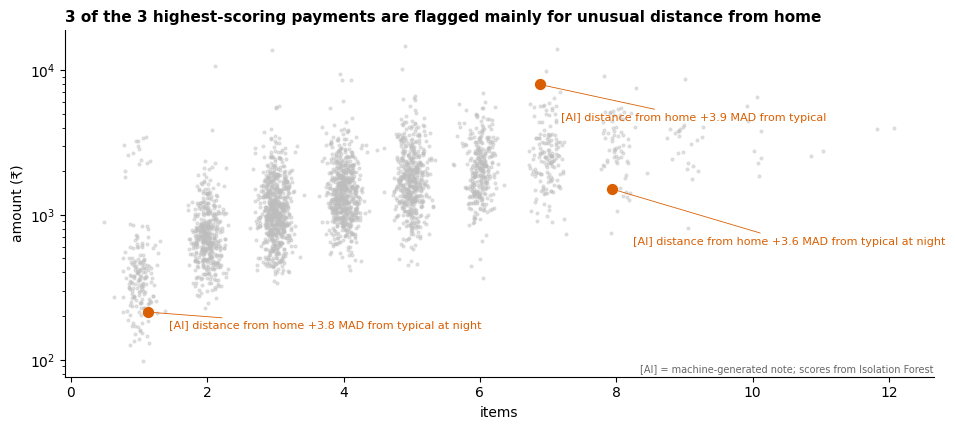

T102419 | [AI] distance from home +3.8 MAD from typical at night | true kind: C: far & at night
T100371 | [AI] distance from home +3.9 MAD from typical | true kind: normal
T100280 | [AI] distance from home +3.6 MAD from typical at night | true kind: C: far & at night


In [22]:
F = features(tx)[["log_amount", "log_amount_per_item", "log_km", "items"]]
rz = (F - F.median()) / (1.4826 * F.apply(stats.median_abs_deviation))
pretty = {"log_amount": "amount", "log_amount_per_item": "amount per item", "log_km": "distance from home", "items": "basket size"}

def reason(i):
    r = rz.loc[i]; col = r.abs().idxmax()
    night = " at night" if tx.hour[i] in (0, 1, 2, 3, 4) else ""
    return f"[AI] {pretty[col]} {r[col]:+.1f} MAD from typical{night}"

def reason_feature(i): return pretty[rz.loc[i].abs().idxmax()]

top3 = tx.nlargest(3, "ai_score").index
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.scatter(tx["items"] + jit, tx.amount, s=4, color=GREY, alpha=.4)
for k_, i in enumerate(top3):
    ax.scatter(tx["items"][i] + jit[i], tx.amount[i], s=50, color=ACCENT, zorder=3)
    ax.annotate(reason(i), (tx["items"][i] + jit[i], tx.amount[i]), xytext=(15, -12 - 14 * k_), textcoords="offset points", fontsize=8, color=ACCENT,
                arrowprops=dict(arrowstyle="-", color=ACCENT, lw=.6))
ax.set_yscale("log"); ax.set_xlabel("items"); ax.set_ylabel("amount (₹)")
drivers = pd.Series([reason_feature(i) for i in top3]).value_counts()
ax.set_title(f"{drivers.iloc[0]} of the 3 highest-scoring payments are flagged mainly for unusual {drivers.index[0]}", loc="left", fontweight="bold", fontsize=11)
ax.text(1, 0.01, "[AI] = machine-generated note; scores from Isolation Forest", transform=ax.transAxes, ha="right", fontsize=7, color="#666")
plt.tight_layout(); plt.show()
for i in top3: print(tx.tx_id[i], "|", reason(i), "| true kind:", tx.kind[i])

## 17 · Human verification of detected patterns

Flagged cases are **candidates, not conclusions**. The analyst inspects each in context, confirms or dismisses it, and the decisions flow back to tune thresholds and labels (Munzner §3.4.1: *discover* and *verify*). Below, a simulated review: the "analyst" (our ground truth) works through the queue in score order.

In [23]:
queue = tx[tx.ai_flag == 1].sort_values("ai_score", ascending=False).reset_index(drop=True)
queue["decision"] = np.where(queue.is_anomaly == 1, "confirm", "dismiss")
queue["running precision"] = (queue.decision == "confirm").cumsum() / (queue.index + 1)
display(queue[["tx_id", "ai_score", "amount", "items", "km_from_home", "hour", "decision", "running precision"]].head(12).round(2))
first_dismiss = queue.ai_score[queue.decision == "dismiss"].max()
print(f"Queue: {len(queue)} flags, {(queue.decision == 'confirm').sum()} confirmed. Highest-scoring false alarm had score {first_dismiss:.2f}.")

# feedback loop: reviewed labels suggest a better threshold
grid = np.arange(0.40, 0.80, 0.01)
f1s = [2 * ((tx.ai_score >= g_) & (tx.is_anomaly == 1)).sum() / ((tx.ai_score >= g_).sum() + tx.is_anomaly.sum()) for g_ in grid]
print(f"Feedback: on the reviewed labels, F1 is highest at threshold ≈ {grid[int(np.argmax(f1s))]:.2f} (current {THR}).")

,tx_id,ai_score,amount,items,km_from_home,hour,decision,running precision
0,T102419,1.00,213.0,1,53.9,4,confirm,1.00
1,T100371,0.95,7933.0,7,56.6,19,dismiss,0.50
2,T100280,0.94,1506.0,8,44.9,1,confirm,0.67
3,T101460,0.91,4701.0,6,50.2,0,confirm,0.75
4,T102110,0.90,2840.0,1,3.1,17,confirm,0.80
5,T101323,0.90,3441.0,1,1.0,6,confirm,0.83
6,T101088,0.89,1036.0,7,48.0,3,dismiss,0.71
7,T102991,0.89,2548.0,11,48.0,21,dismiss,0.62
8,T101763,0.88,8642.0,9,7.6,21,dismiss,0.56
9,T102120,0.88,2791.0,8,36.5,3,confirm,0.60


Queue: 89 flags, 32 confirmed. Highest-scoring false alarm had score 0.95.
Feedback: on the reviewed labels, F1 is highest at threshold ≈ 0.71 (current 0.7).


### What the reviewer needs (Munzner §6.5 "eyes beat memory"; Ch. 11–12 linked views)
* **Context**: the surrounding data, not the flagged point alone.
* **Details on demand**: the raw record, the score, the main reason.
* **Linked views**, so a flagged item can be traced across views.
* **A way to act**: confirm / dismiss / label, and see what was already reviewed.

ITEM    : T102419 | ₹213 | 1 items | 53.9 km | 4:00 | Grocery | account 2102 days
SCORE   : 1.00 (higher than 100.0% of payments; threshold 0.7)
REASON  : [AI] distance from home +3.8 MAD from typical at night
PEERS   : median amount for 1-item baskets = ₹374
ACTIONS : [confirm] [dismiss] [label kind] [hide model layer]


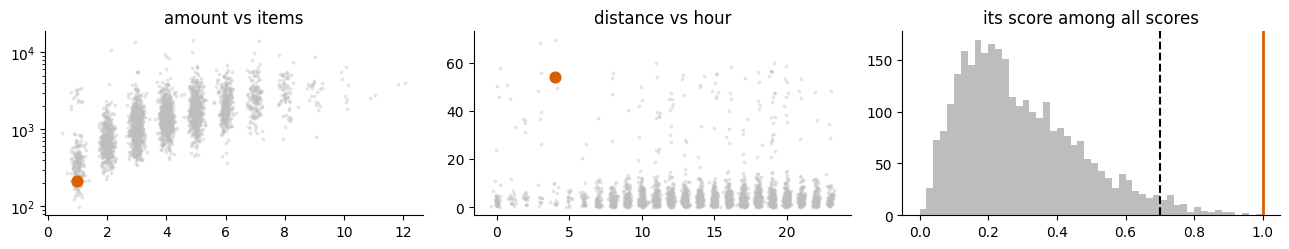

ITEM    : T100766 | ₹1,127 | 3 items | 36.7 km | 2:00 | Grocery | account 1214 days
SCORE   : 0.60 (higher than 93.5% of payments; threshold 0.7)
REASON  : [AI] distance from home +3.3 MAD from typical at night
PEERS   : median amount for 3-item baskets = ₹1,039
ACTIONS : [confirm] [dismiss] [label kind] [hide model layer]


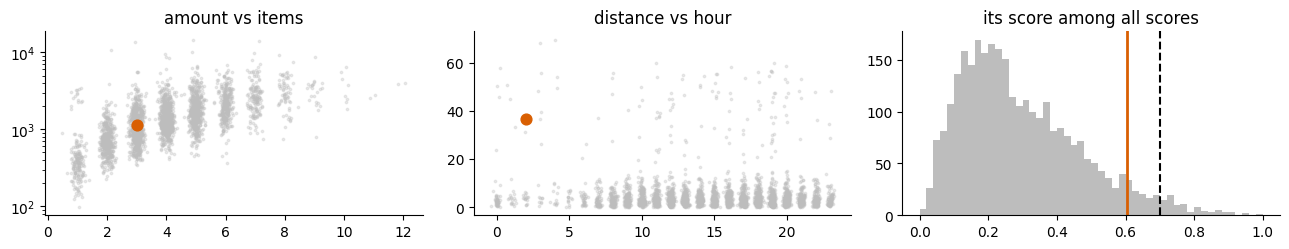

In [24]:
def evidence_card(i):
    r = tx.loc[i]
    pct = (tx.ai_score < r.ai_score).mean() * 100
    print("=" * 80)
    print(f"ITEM    : {r.tx_id} | ₹{r.amount:,.0f} | {r['items']} items | {r.km_from_home} km | {r.hour}:00 | {r.category} | account {r.account_age_days} days")
    print(f"SCORE   : {r.ai_score:.2f} (higher than {pct:.1f}% of payments; threshold {THR})")
    print(f"REASON  : {reason(i)}")
    print(f"PEERS   : median amount for {r['items']}-item baskets = ₹{tx.amount[tx['items'] == r['items']].median():,.0f}")
    print("ACTIONS : [confirm] [dismiss] [label kind] [hide model layer]")
    fig, ax = plt.subplots(1, 3, figsize=(13, 2.6))
    ax[0].scatter(tx["items"] + jit, tx.amount, s=3, color=GREY, alpha=.3); ax[0].scatter(r["items"], r.amount, color=ACCENT, s=60); ax[0].set_yscale("log"); ax[0].set_title("amount vs items")
    ax[1].scatter(tx.hour + jit, tx.km_from_home, s=3, color=GREY, alpha=.3); ax[1].scatter(r.hour, r.km_from_home, color=ACCENT, s=60); ax[1].set_title("distance vs hour")
    ax[2].hist(tx.ai_score, bins=50, color=GREY); ax[2].axvline(r.ai_score, color=ACCENT, lw=2); ax[2].axvline(THR, color="k", ls="--"); ax[2].set_title("its score among all scores")
    plt.tight_layout(); plt.show()

evidence_card(queue.tx_id.map(dict(zip(tx.tx_id, tx.index)))[0])
evidence_card(tx[tx.kind.str.startswith("C")].ai_score.idxmin())

## 18 · False positives, false negatives and thresholds

|  | Flagged | Not flagged |
|---|---|---|
| **Truly anomalous** | TP: caught | **FN: missed** (often the more costly error) |
| **Truly normal** | **FP: false alarm** (wastes review effort) | TN: correctly ignored |

Lower threshold → more true alarms but many false ones; higher threshold → fewer false alarms but real anomalies missed. **Choose the cut-off from the relative costs**, not from the score alone.

,flagged,not flagged
truly anomalous,32,13
truly normal,57,2898


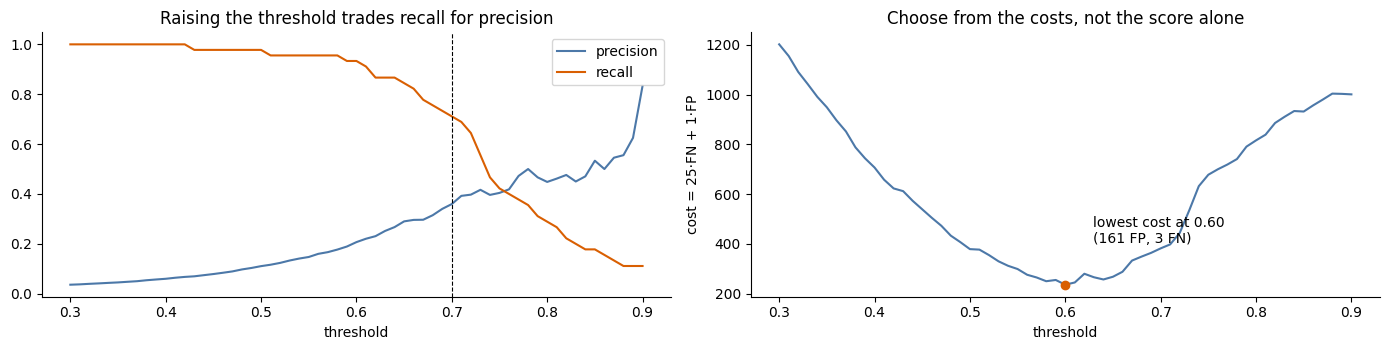

In [25]:
def confusion(thr):
    f_ = tx.ai_score >= thr; t_ = tx.is_anomaly == 1
    return dict(TP=int((f_ & t_).sum()), FP=int((f_ & ~t_).sum()), FN=int((~f_ & t_).sum()), TN=int((~f_ & ~t_).sum()))

cmx = confusion(THR)
display(pd.DataFrame([[cmx["TP"], cmx["FN"]], [cmx["FP"], cmx["TN"]]], index=["truly anomalous", "truly normal"], columns=["flagged", "not flagged"]))

grid = np.round(np.arange(0.30, 0.90, 0.01), 2)
sweep = pd.DataFrame([dict(thr=g_, **confusion(g_)) for g_ in grid])
sweep["precision"] = sweep.TP / (sweep.TP + sweep.FP).replace(0, np.nan)
sweep["recall"] = sweep.TP / (sweep.TP + sweep.FN)
COST_FN, COST_FP = 25, 1
sweep["cost"] = COST_FN * sweep.FN + COST_FP * sweep.FP
best = sweep.loc[sweep.cost.idxmin()]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].plot(sweep.thr, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.thr, sweep.recall, color=ACCENT, label="recall")
ax[0].axvline(THR, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold"); ax[0].set_title("Raising the threshold trades recall for precision")
ax[1].plot(sweep.thr, sweep.cost, color=BLUE); ax[1].scatter(best.thr, best.cost, color=ACCENT, zorder=3)
ax[1].annotate(f"lowest cost at {best.thr:.2f}\n({int(best.FP)} FP, {int(best.FN)} FN)", (best.thr, best.cost), xytext=(20, 30), textcoords="offset points")
ax[1].set_xlabel("threshold"); ax[1].set_ylabel(f"cost = {COST_FN}·FN + {COST_FP}·FP"); ax[1].set_title("Choose from the costs, not the score alone")
plt.tight_layout(); plt.show()

## 19 · Measuring detector quality and the accuracy trap

**Precision** = TP / (TP + FP): of everything flagged, how much was real? **Recall** = TP / (TP + FN): of all real anomalies, how many were found? **F1** balances them. **Accuracy** = (TP + TN) / all looks excellent when anomalies are rare; a detector that flags nothing scores high.

In [26]:
def quality(c):
    p = c["TP"] / (c["TP"] + c["FP"]) if c["TP"] + c["FP"] else 0; r = c["TP"] / (c["TP"] + c["FN"])
    return dict(precision=round(p, 2), recall=round(r, 2), F1=round(2 * p * r / (p + r), 2) if p + r else 0, accuracy=round((c["TP"] + c["TN"]) / sum(c.values()), 3))

display(pd.DataFrame({f"Isolation Forest @ {THR:.2f} (default)": quality(confusion(THR)), f"Isolation Forest @ {best.thr:.2f} (cost-based)": quality(confusion(best.thr)),
                      "flag nothing": quality(dict(TP=0, FP=0, FN=int(tx.is_anomaly.sum()), TN=int(N - tx.is_anomaly.sum())))}).T)
print("The do-nothing detector has ~98.5% accuracy and catches nothing. Report precision and recall.")

,precision,recall,F1,accuracy
Isolation Forest @ 0.70 (default),0.36,0.71,0.48,0.977
Isolation Forest @ 0.60 (cost-based),0.21,0.93,0.34,0.945
flag nothing,0.00,0.00,0.00,0.985


The do-nothing detector has ~98.5% accuracy and catches nothing. Report precision and recall.


## 20 · Uncertainty in algorithmic findings (Wilke Ch. 16)

Scores, baselines and cluster assignments are **estimates**. Showing no uncertainty invites over-confident reading, but uncertainty displays can themselves be misread as hard boundaries. **A flag near the threshold and a flag far beyond it are different findings and should not look alike.**

### 20a · How stable is each score? Re-run the detector with 15 random seeds

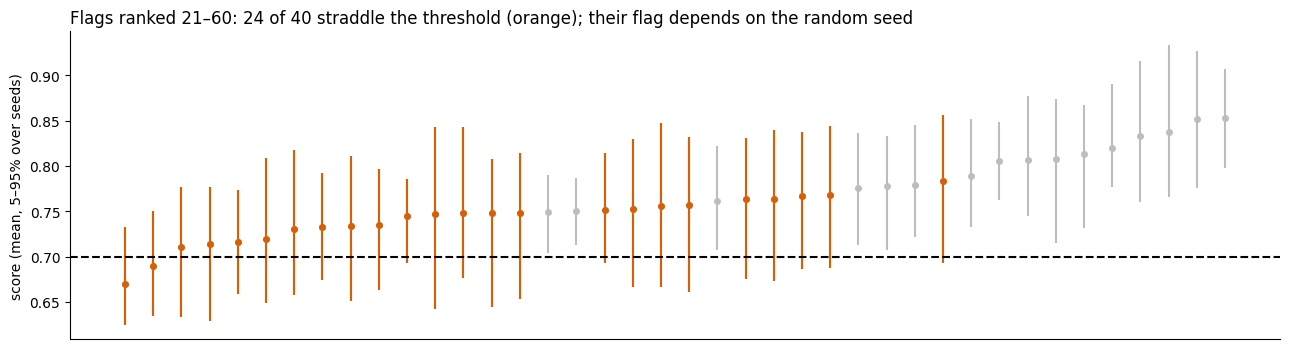

In [27]:
runs = []
for s_ in range(15):
    r_ = -IsolationForest(n_estimators=100, random_state=s_ + 10).fit(X).score_samples(X)
    runs.append((r_ - raw.min()) / (raw.max() - raw.min()))
runs = np.array(runs)
cand = tx.ai_score.sort_values(ascending=False).index[20:60]
mu, lo_, hi_ = runs[:, cand].mean(0), np.percentile(runs[:, cand], 5, axis=0), np.percentile(runs[:, cand], 95, axis=0)
o = np.argsort(mu)
fig, ax = plt.subplots(figsize=(13, 3.6))
crosses = (lo_ < THR) & (hi_ >= THR)
ax.errorbar(range(len(cand)), mu[o], yerr=[mu[o] - lo_[o], hi_[o] - mu[o]], fmt="o", ms=4, color=GREY, ecolor=GREY)
ax.errorbar(np.where(crosses[o])[0], mu[o][crosses[o]], yerr=[(mu - lo_)[o][crosses[o]], (hi_ - mu)[o][crosses[o]]], fmt="o", ms=4, color=ACCENT, ecolor=ACCENT)
ax.axhline(THR, color="k", ls="--"); ax.set_xticks([]); ax.set_ylabel("score (mean, 5–95% over seeds)")
ax.set_title(f"Flags ranked 21–60: {crosses.sum()} of {len(cand)} straddle the threshold (orange); their flag depends on the random seed", loc="left")
plt.tight_layout(); plt.show()

### 20b · Error bars: always say what they show
The same baseline (the 7 Mondays' transaction counts) with three different bars. SD describes the spread of observations; SE the precision of the mean; a CI is about ±2 SE.

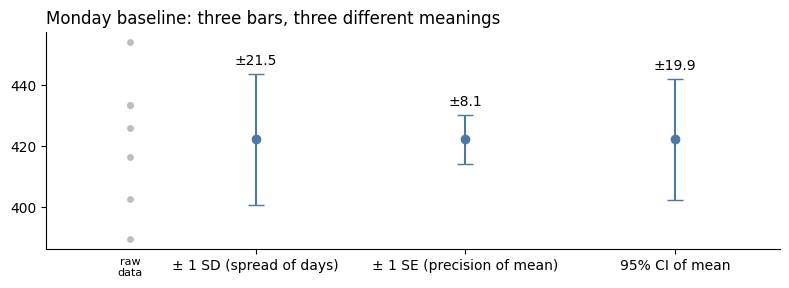

In [28]:
mon = pd.Series(y[days.day_of_week == 0][:7])
sd, se = mon.std(), mon.std() / np.sqrt(len(mon))
ci = stats.t.ppf(.975, len(mon) - 1) * se
fig, ax = plt.subplots(figsize=(8, 3))
for k_, (lab, half) in enumerate([("± 1 SD (spread of days)", sd), ("± 1 SE (precision of mean)", se), ("95% CI of mean", ci)]):
    ax.errorbar(k_, mon.mean(), yerr=half, fmt="o", color=BLUE, capsize=6); ax.text(k_, mon.mean() + half + 3, f"±{half:.1f}", ha="center")
ax.scatter(np.full(7, -0.6), mon, color=GREY, s=15); ax.text(-0.6, mon.min() - 12, "raw\ndata", ha="center", fontsize=8)
ax.set_xticks(range(3)); ax.set_xticklabels(["± 1 SD (spread of days)", "± 1 SE (precision of mean)", "95% CI of mean"]); ax.set_xlim(-1, 2.5)
ax.set_title("Monday baseline: three bars, three different meanings", loc="left"); plt.tight_layout(); plt.show()

### 20c · Confidence band on a baseline, and hypothetical outcomes
A baseline fit gets a **band, not a single line**. A **hypothetical outcome plot** (Wilke Ch. 16) shows several plausible fits; here a candidate day near the edge is "anomalous" under some fits and not under others: **the verdict flips.**

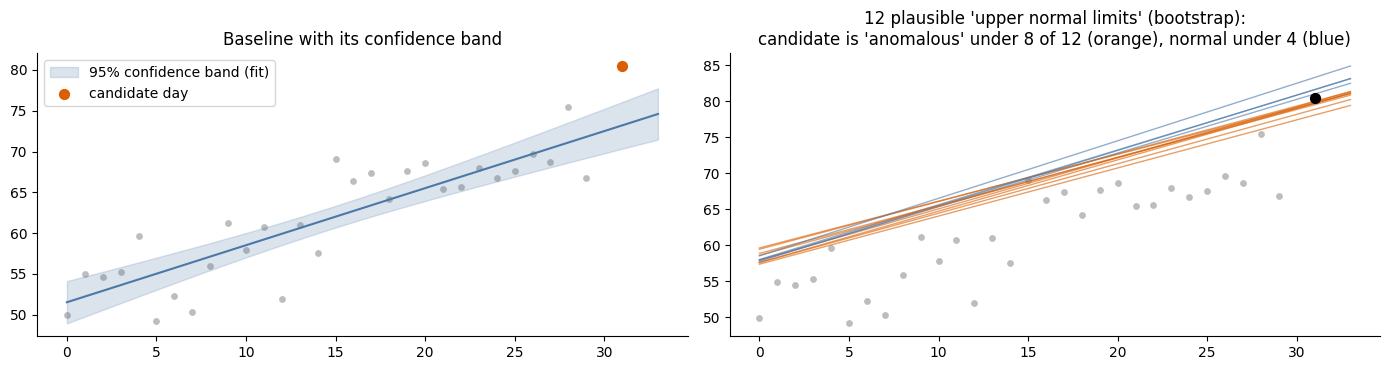

The verdict flips between plausible baselines: call it a candidate, show the score with its uncertainty.


In [29]:
rs = np.random.default_rng(12)
xx = np.arange(30); yy = 50 + 0.8 * xx + rs.normal(0, 4, 30)
lr = stats.linregress(xx, yy)
resid_sd = np.std(yy - (lr.intercept + lr.slope * xx), ddof=2)
cand_x = 31; cand_y = lr.intercept + lr.slope * cand_x + 2.0 * resid_sd          # a new day right at the edge
gx = np.linspace(0, 33, 100)
se_fit = resid_sd * np.sqrt(1 / 30 + (gx - xx.mean()) ** 2 / ((xx - xx.mean()) ** 2).sum())
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].scatter(xx, yy, color=GREY, s=15); ax[0].plot(gx, lr.intercept + lr.slope * gx, color=BLUE)
ax[0].fill_between(gx, lr.intercept + lr.slope * gx - 2 * se_fit, lr.intercept + lr.slope * gx + 2 * se_fit, color=BLUE, alpha=.2, label="95% confidence band (fit)")
ax[0].scatter(cand_x, cand_y, color=ACCENT, s=50, zorder=3, label="candidate day"); ax[0].legend(); ax[0].set_title("Baseline with its confidence band")
flips = 0
for k_ in range(12):
    bi = rs.integers(0, 30, 30); l_ = stats.linregress(xx[bi], yy[bi])
    sd_k = np.std(yy[bi] - (l_.intercept + l_.slope * xx[bi]), ddof=2)
    out = cand_y > l_.intercept + l_.slope * cand_x + 2 * sd_k
    flips += out
    ax[1].plot(gx, l_.intercept + l_.slope * gx + 2 * sd_k, color=ACCENT if out else BLUE, alpha=.6, lw=1)
ax[1].scatter(xx, yy, color=GREY, s=15); ax[1].scatter(cand_x, cand_y, color="k", s=50, zorder=3)
ax[1].set_title(f"12 plausible 'upper normal limits' (bootstrap):\ncandidate is 'anomalous' under {flips} of 12 (orange), normal under {12 - flips} (blue)")
plt.tight_layout(); plt.show()
print("The verdict flips between plausible baselines: call it a candidate, show the score with its uncertainty.")

### 20d · Frequency framing of an alert probability (Wilke Ch. 16)
"70% likely a real anomaly" is harder to grasp than **"of 10 similar flagged cases, about 7 were real."** We compute the real share in a score band from the reviewed queue and draw it as dots.

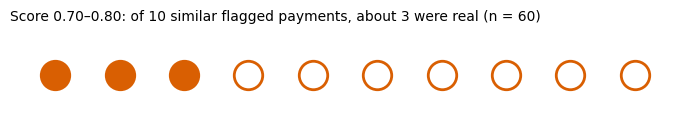

In [30]:
band = tx[(tx.ai_score >= THR) & (tx.ai_score < THR + 0.1)]
share = band.is_anomaly.mean(); k_real = int(round(share * 10))
fig, ax = plt.subplots(figsize=(7, 1.4))
for i in range(10):
    ax.scatter(i, 0, s=420, color=ACCENT if i < k_real else "white", edgecolors=ACCENT, linewidths=2)
ax.set_xlim(-.7, 9.7); ax.axis("off")
ax.set_title(f"Score {THR:.2f}–{THR + 0.1:.2f}: of 10 similar flagged payments, about {k_real} were real (n = {len(band)})", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 21 · Saliency and attention in AI-generated highlights (Ware Ch. 5)

Salient items attract the eye first (Ware G1.2: important data should look more distinct). But **an AI highlight is salient because of the model, not because it is important.** Attention is limited, and unexpected events outside the attended region are easily missed (inattentional blindness). So highlights pull attention **toward** flagged items and **away** from unflagged ones, where the missed anomalies (FN) hide.

### When highlights lose their power
Pop-out works when the highlight is **rare** (G5.6). Flag too much and nothing stands out. **Graded emphasis** restores a ranking.

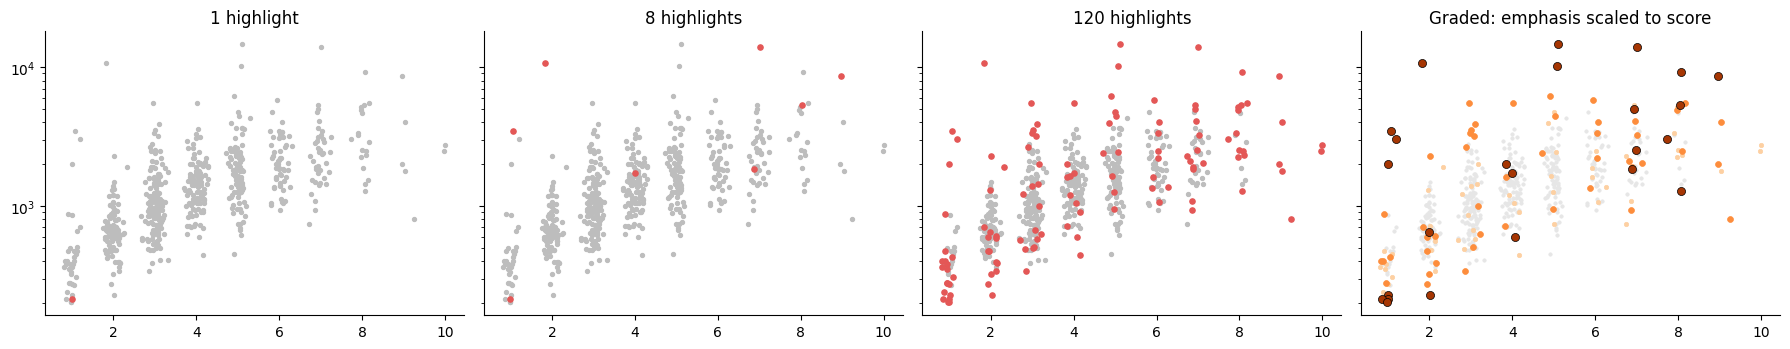

Missed anomalies (FN) at threshold 0.7: 13, drawn in grey like everything else:
kind
A: huge amount               7
C: far & at night            3
B: amount/basket mismatch    3


In [31]:
sub = tx.sample(600, random_state=0)
sj = rng.normal(0, .12, len(sub))
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for a_, k_ in zip(ax[:3], [1, 8, 120]):
    hi_i = sub.nlargest(k_, "ai_score").index
    a_.scatter(sub["items"] + sj, sub.amount, s=8, color=GREY)
    a_.scatter(sub.loc[hi_i, "items"] + sj[sub.index.get_indexer(hi_i)], sub.loc[hi_i, "amount"], s=14, color="#e45756")
    a_.set_title(f"{k_} highlight{'s' if k_ > 1 else ''}"); a_.set_yscale("log")
bands = [(0.0, .45, LIGHT, 6, None), (.45, .55, "#fdd0a2", 10, None), (.55, .7, "#fd8d3c", 18, None), (.7, 1.01, "#a63603", 34, "k")]
for lo_b, hi_b, col, sz, ec in bands:
    mm = (sub.ai_score >= lo_b) & (sub.ai_score < hi_b)
    ax[3].scatter(sub["items"][mm] + sj[mm.values], sub.amount[mm], s=sz, color=col, edgecolors=ec, linewidths=.5)
ax[3].set_title("Graded: emphasis scaled to score")
plt.tight_layout(); plt.show()

fn = tx[(tx.is_anomaly == 1) & (tx.ai_flag == 0)]
print(f"Missed anomalies (FN) at threshold {THR}: {len(fn)}, drawn in grey like everything else:")
print(fn.kind.value_counts().to_string())

### Alerting, cognitive load and avoiding overemphasis
* Ware G5.19: peripheral alert cues must be **stronger when cognitive load is high**; G5.9: subtle motion can highlight when colour and shape are taken.
* Constant strong alerts cause **fatigue** and are eventually ignored: reserve the strongest cues for the few cases that need immediate action.
* **Scale emphasis to confidence and importance**; keep all data visible; make the model layer a **toggle**; call flags **candidates** and show the score (Parasuraman & Manzey 2010 on automation bias).

### Design checklist: emphasis scaled to confidence

In [32]:
def emphasis(score):
    if score >= .90: return "strong hue + label + top of queue", "review first"
    if score >= .70: return "moderate hue, smaller mark", "review in order"
    if score >= .50: return "subtle outline only", "skim; sample"
    return "no emphasis; data stays visible", "not queued"

bands_tbl = []
for lo_b, hi_b, lab in [(.9, 1.01, "High (≥ 0.90)"), (.7, .9, "Medium (0.70–0.90)"), (.5, .7, "Low (0.50–0.70)"), (0, .5, "Below 0.50")]:
    mm = (tx.ai_score >= lo_b) & (tx.ai_score < hi_b)
    enc, act = emphasis(lo_b)
    bands_tbl.append((lab, enc, act, int(mm.sum()), round(tx.is_anomaly[mm].mean(), 2) if mm.any() else np.nan))
display(pd.DataFrame(bands_tbl, columns=["score band", "encoding", "reviewer action", "items", "share truly anomalous"]))

,score band,encoding,reviewer action,items,share truly anomalous
0,High (≥ 0.90),strong hue + label + top of queue,review first,6,0.83
1,Medium (0.70–0.90),"moderate hue, smaller mark",review in order,83,0.33
2,Low (0.50–0.70),subtle outline only,skim; sample,309,0.04
3,Below 0.50,no emphasis; data stays visible,not queued,2602,0.00


## 22 · Putting it together: an anomaly review view
Main view: raw data with **one sparing cue**, graded by score · Context: baselines with uncertainty · Queue: ranked flags with a short reason and confidence · Verification: details on demand, confirm/dismiss, model-layer toggle · Evaluation: precision, recall, review time.

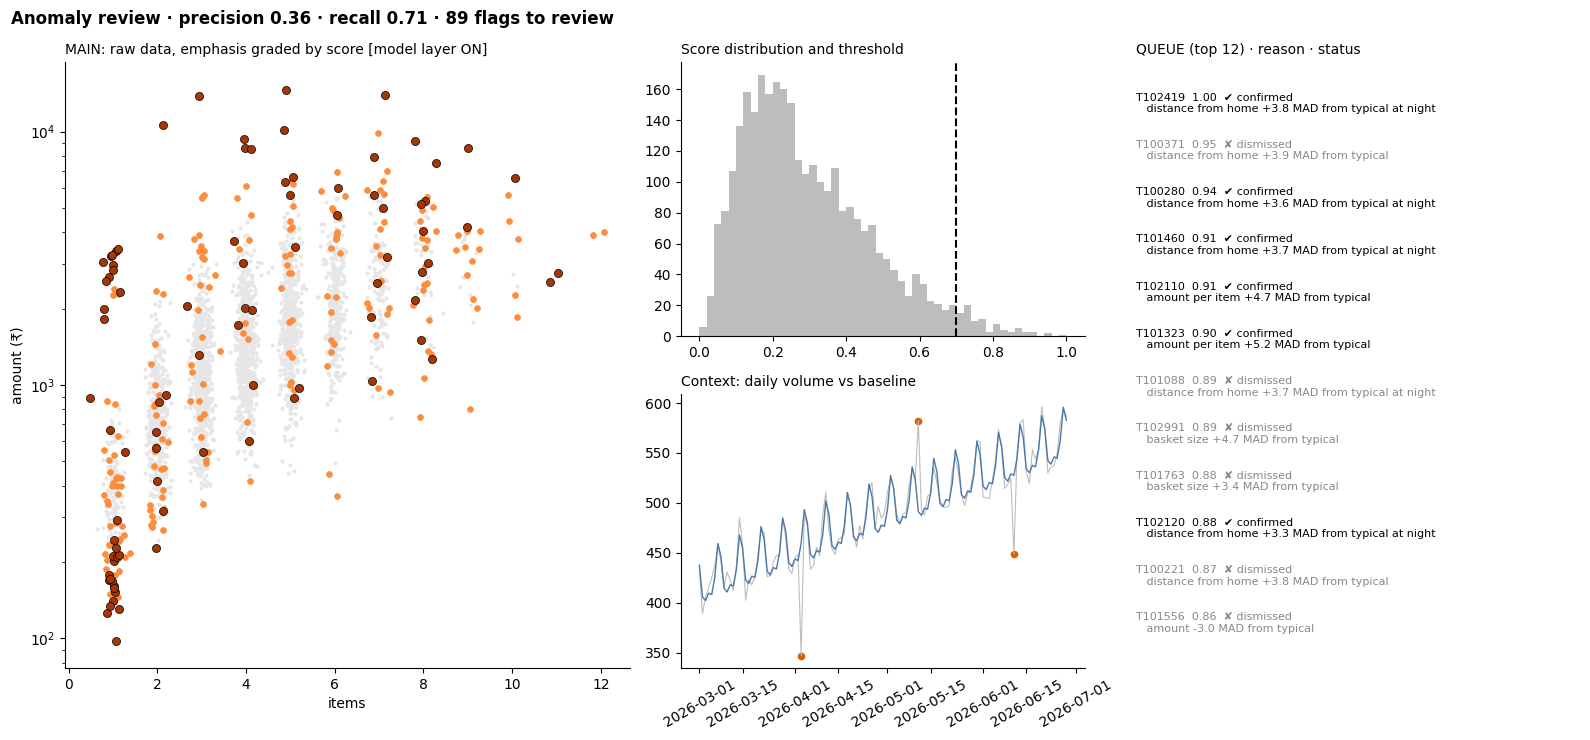

In [33]:
fig = plt.figure(figsize=(16, 7.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1.4, 1, 1.1])
a0 = fig.add_subplot(gs[:, 0]); a1 = fig.add_subplot(gs[0, 1]); a2 = fig.add_subplot(gs[1, 1]); a3 = fig.add_subplot(gs[:, 2])
a0.scatter(tx["items"] + jit, tx.amount, s=4, color=LIGHT)
for lo_b, hi_b, col, sz, ec in bands[2:]:
    mm = (tx.ai_score >= lo_b) & (tx.ai_score < hi_b)
    a0.scatter(tx["items"][mm] + jit[mm], tx.amount[mm], s=sz, color=col, edgecolors=ec, linewidths=.5)
a0.set_yscale("log"); a0.set_xlabel("items"); a0.set_ylabel("amount (₹)"); a0.set_title("MAIN: raw data, emphasis graded by score [model layer ON]", loc="left", fontsize=10)
a1.hist(tx.ai_score, bins=50, color=GREY); a1.axvline(THR, color="k", ls="--"); a1.set_title("Score distribution and threshold", loc="left", fontsize=10)
a2.plot(days, y, color=GREY, lw=.8); a2.plot(days, fit, color=BLUE, lw=1); a2.scatter(days[odd], y[odd], color=ACCENT, s=20); a2.set_title("Context: daily volume vs baseline", loc="left", fontsize=10)
a2.tick_params(axis="x", rotation=30)
a3.axis("off"); a3.set_title("QUEUE (top 12) · reason · status", loc="left", fontsize=10)
for k_, (_, r) in enumerate(queue.head(12).iterrows()):
    i = tx.index[tx.tx_id == r.tx_id][0]
    a3.text(0, 0.95 - k_ * 0.078, f"{r.tx_id}  {r.ai_score:.2f}  {'✔ confirmed' if r.decision == 'confirm' else '✘ dismissed'}\n   {reason(i)[5:]}", fontsize=8,
            color="k" if r.decision == "confirm" else "#888", transform=a3.transAxes, va="top")
q_ = quality(confusion(THR))
fig.suptitle(f"Anomaly review · precision {q_['precision']} · recall {q_['recall']} · {cmx['TP'] + cmx['FP']} flags to review", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 23 · Worked numericals

### Numerical 1: z-score and IQR outlier rules
Ten response times (ms): 48, 52, 50, 47, 55, 49, 51, 53, 46, 98. Is 98 flagged by (a) |z| > 3 and (b) the 1.5 × IQR rule?

In [34]:
v = np.array([48, 52, 50, 47, 55, 49, 51, 53, 46, 98])
mean, sd_ = v.mean(), v.std(ddof=1)
print(f"mean = {v.sum()} / {len(v)} = {mean}; sum of squared deviations = {((v - mean) ** 2).sum():.1f}; sample SD = {sd_:.1f}")
print(f"(a) z(98) = (98 - {mean}) / {sd_:.1f} = {(98 - mean) / sd_:.2f}  -> NOT flagged (masking: the outlier inflated the SD)")
s = np.sort(v); q1_, q3_ = np.median(s[:5]), np.median(s[5:])
print(f"(b) sorted {s.tolist()}; Q1 = {q1_}, Q3 = {q3_}, IQR = {q3_ - q1_}; fences {q1_ - 1.5 * (q3_ - q1_)} and {q3_ + 1.5 * (q3_ - q1_)} -> 98 IS flagged")
print(f"Bonus: with n = 10 the largest possible |z| is (n-1)/sqrt(n) = {9 / np.sqrt(10):.2f}, so '|z| > 3' can never fire on 10 points.")

mean = 549 / 10 = 54.9; sum of squared deviations = 2132.9; sample SD = 15.4
(a) z(98) = (98 - 54.9) / 15.4 = 2.80  -> NOT flagged (masking: the outlier inflated the SD)
(b) sorted [46, 47, 48, 49, 50, 51, 52, 53, 55, 98]; Q1 = 48.0, Q3 = 53.0, IQR = 5.0; fences 40.5 and 60.5 -> 98 IS flagged
Bonus: with n = 10 the largest possible |z| is (n-1)/sqrt(n) = 2.85, so '|z| > 3' can never fire on 10 points.


### Numerical 2: precision, recall, F1 and the accuracy trap
1,000 events contain 45 true anomalies. A detector flags 50; 36 are real.

In [35]:
TP, flagged, real, total = 36, 50, 45, 1000
FP, FN = flagged - TP, real - TP; TN = total - TP - FP - FN
P_, R_ = TP / flagged, TP / real
print(f"TP={TP}, FP={FP}, FN={FN}, TN={TN}")
print(f"precision = {P_:.2f} | recall = {R_:.2f} | F1 = {2 * P_ * R_ / (P_ + R_):.2f} | accuracy = {(TP + TN) / total:.1%} | flag-nothing accuracy = {(total - real) / total:.1%}")
print("MCQ 4 check: recall = 36 / 45 =", round(36 / 45, 2))

TP=36, FP=14, FN=9, TN=941
precision = 0.72 | recall = 0.80 | F1 = 0.76 | accuracy = 97.7% | flag-nothing accuracy = 95.5%
MCQ 4 check: recall = 36 / 45 = 0.8


### Numerical 3: the base-rate problem
Anomalies are 0.5% of 10,000 events. The detector catches 95% of true anomalies and falsely flags 2% of normal events. What fraction of alerts are real?

true anomalies = 50; caught = 47.5; false alarms = 0.02 x 9950 = 199
precision = 47.5 / 246.5 = 19.3%  -> about 4 of every 5 alerts are false


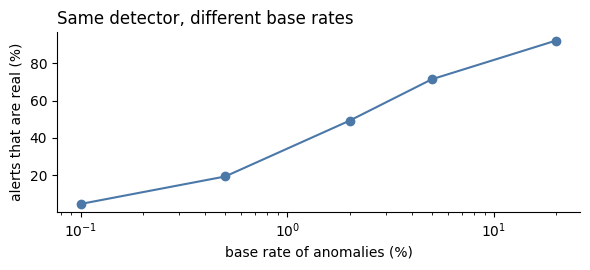

In [36]:
n_, base_rate, tpr, fpr = 10_000, 0.005, 0.95, 0.02
anom = base_rate * n_; caught = tpr * anom; false_al = fpr * (n_ - anom)
print(f"true anomalies = {anom:.0f}; caught = {caught}; false alarms = {fpr} x {n_ - anom:.0f} = {false_al:.0f}")
print(f"precision = {caught} / {caught + false_al} = {caught / (caught + false_al):.1%}  -> about 4 of every 5 alerts are false")
rates = np.array([0.001, 0.005, 0.02, 0.05, 0.2])
prec = tpr * rates / (tpr * rates + fpr * (1 - rates))
plt.figure(figsize=(6, 2.8)); plt.plot(rates * 100, prec * 100, marker="o", color=BLUE); plt.xscale("log")
plt.xlabel("base rate of anomalies (%)"); plt.ylabel("alerts that are real (%)"); plt.title("Same detector, different base rates", loc="left"); plt.tight_layout(); plt.show()

### Numerical 4: standard deviation versus standard error
A baseline has mean 100 and SD 12 from n = 36 readings. A new reading is 125.

In [37]:
mu0, sd0, n0, new = 100, 12, 36, 125
se0 = sd0 / np.sqrt(n0)
print(f"SE = {sd0} / sqrt({n0}) = {se0}; 95% CI for the MEAN ≈ {mu0 - 2 * se0:.0f} to {mu0 + 2 * se0:.0f}")
print(f"Correct (a single reading varies like the data): z = ({new} - {mu0}) / {sd0} = {(new - mu0) / sd0:.2f}  -> borderline")
print(f"Wrong (using SE): z = {new - mu0} / {se0} = {(new - mu0) / se0:.1f}  -> wildly overstates how unusual it is (false positives)")

SE = 12 / sqrt(36) = 2.0; 95% CI for the MEAN ≈ 96 to 104
Correct (a single reading varies like the data): z = (125 - 100) / 12 = 2.08  -> borderline
Wrong (using SE): z = 25 / 2.0 = 12.5  -> wildly overstates how unusual it is (false positives)


## Summary

| Theme | Take-away |
|---|---|
| **Derived attributes** | AI output (score, cluster ID, flag) is a derived attribute: magnitude channels for scores, identity channels for IDs; a binary flag hides closeness to the threshold |
| **Distribution & association views** | histograms, densities, scatterplots, PCA show outliers directly; bin width and bandwidth change what looks anomalous |
| **Detectors** | univariate rules see only extreme values; joint anomalies need multivariate detectors; k-means forces outliers into clusters, DBSCAN labels them noise |
| **Anomaly types** | point → highlight a mark · contextual → show the context · collective → highlight the span |
| **Errors** | FP and FN trade off through the threshold; choose from costs; report precision and recall, not accuracy |
| **Uncertainty** | scores near the threshold are unstable; label error bars; frame probabilities as frequencies |
| **Saliency** | highlights are salient whether or not they are important: keep them rare, grade them by confidence, never hide the unflagged data |

*Next: try the companion activity notebook, which uses a different synthetic dataset (`freshkart_coldchain.csv`).*